# ENG2440 Assignment 2 — Whole-tumour segmentation in multimodal 3D MRI

Patch-based 3D U-Net trained on MSD Task01 BrainTumour (four co-registered MRI channels per case), with a controlled comparison of uniform and tumour-aware patch sampling, overlapping sliding-window reconstruction, and evaluation in physical units (Dice, IoU, sensitivity, HD95 in mm, volume in mL).

**Repository:** <https://github.com/chairlamp/brats-3d-unet-segmentation> *(private; link also in the report)*

**How to run.** Change only `DATA_ROOT` in the first code cell, then run all cells from the top with this folder as the working directory. `README.md` lists the environment, run order, runtimes and seeds. Trained weights in `models/` are reused when their configuration matches `a2/experiments.py`; otherwise Section 4 trains them (about 70 min per run on an Apple M4 Max). Section 10 does the same for the two longer v2 runs (about 4.5 h each).

Supporting code is in `a2/`: `data.py` (loading, geometry, preprocessing), `sampling.py` (patch dataset, samplers, augmentation), `model.py` (3D U-Net), `train.py` (training loop), `inference.py` (sliding window), `metrics.py`, `evaluate.py`, `viz.py`; for the v2 model of Section 10: `fastconv.py` (exact, faster 3D convolutions on Apple MPS), `sampling_v2.py` (stronger augmentation), `train_v2.py` (training) and `final_v2.py` (inference and validation-only selection).

This is a learning exercise on a research dataset, not a clinical tool.

In [1]:
import json
import platform
import subprocess
import time
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
import scipy
import torch
from IPython.display import display
from scipy import ndimage, stats
from torch.utils.data import DataLoader

# =====================================================================================
# DATA_ROOT: the only line to change. Folder containing imagesTr/, labelsTr/, dataset.json
DATA_ROOT = Path("Task01_BrainTumour")
# =====================================================================================

SPLIT_FILE = Path("assignment2_split.csv")
CACHE_DIR, MODEL_DIR, PRED_DIR, RESULTS_DIR = Path("cache"), Path("models"), Path("predictions"), Path("results")
FIG_DIR = Path("report/figures")
for d in (CACHE_DIR, MODEL_DIR, PRED_DIR, RESULTS_DIR, FIG_DIR):
    d.mkdir(exist_ok=True, parents=True)


def save(fig, name):
    # Save a figure for the report (vector PDF; image panels are embedded at full resolution)
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight", dpi=200)

from a2 import data, viz
from a2 import evaluate as ev
from a2.experiments import EXPERIMENTS
from a2.inference import n_windows, sliding_window_probs, window_starts
from a2.metrics import dice, voxel_volume_ml
from a2.model import UNet3D, count_parameters
from a2.sampling import PatchDataset, augment, tumour_fraction
from a2.train import pick_device, seed_everything, train

SEED = 2440
seed_everything(SEED)
DEVICE = pick_device()
viz.apply_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 100)

chip = platform.processor()
if platform.system() == "Darwin":
    chip = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True).stdout.strip()
print(f"Python {platform.python_version()} | PyTorch {torch.__version__} | nibabel {nib.__version__} | "
      f"NumPy {np.__version__} | SciPy {scipy.__version__}")
print(f"Hardware: {chip}, device used: {DEVICE}")

Python 3.12.15 | PyTorch 2.15.0 | nibabel 5.4.2 | NumPy 2.5.4 | SciPy 1.18.1
Hardware: Apple M4 Max, device used: mps


## 1. Task definition and volume inspection

### 1.1 Task

| | |
|---|---|
| **Input** | One patient case: a 4-channel 3D MRI volume (FLAIR, T1w, T1gd = contrast-enhanced T1, T2w), co-registered, skull-stripped, 240 × 240 × 155 voxels at 1 mm isotropic spacing, as a float tensor `[4, D, H, W]`. |
| **Output** | A binary whole-tumour mask on the same voxel grid, `[1, D, H, W]`: 1 where the voxel belongs to any annotated tumour sub-region (edema, non-enhancing tumour, enhancing tumour), else 0. The network outputs a per-voxel probability, thresholded at 0.5. |
| **Unit of analysis** | The patient case. Splitting, metrics and summary statistics are all per case; voxels and patches from one case are never spread across splits. |
| **Intended technical use** | Automatic delineation of whole-tumour extent and volume (mL) on research MRI, for studying volumetric segmentation methods. The target is a research reference segmentation, not pathology-confirmed tumour extent; nothing here establishes clinical safety or suitability for treatment planning. |

**Voxel, slice, volume, case.** A *voxel* is one 1 × 1 × 1 mm³ sample of the grid, with four intensities (one per channel) and one label. A *slice* is a 2D plane of voxels at one index along one axis (axial, coronal or sagittal); 155 axial slices make one volume. A *volume* is the full 3D grid for one acquisition, here 240 × 240 × 155 voxels per channel. A *case* is one patient: in MSD Task01 each case is exactly one 4-channel volume and one label volume, so case = patient = one volume set. Slices and patches from the same case are strongly correlated, which is why the split is at case level.

In [2]:
dataset_json = json.loads((DATA_ROOT / "dataset.json").read_text())
print("Channel order (4th NIfTI axis), from dataset.json:", dataset_json["modality"])
print("Label values, from dataset.json:", dataset_json["labels"])
CHANNELS = data.CHANNELS

split_df = data.load_split(SPLIT_FILE, DATA_ROOT)
by_id = split_df.set_index("case_id")
inspect_ids = split_df.loc[split_df.split == "train", "case_id"].iloc[:3].tolist()  # training cases only

rows = []
for cid in inspect_ids:
    im, lb = nib.load(by_id.loc[cid, "image_path"]), nib.load(by_id.loc[cid, "label_path"])
    lbl = np.asarray(lb.dataobj)
    vals, counts = np.unique(lbl, return_counts=True)
    rows.append({
        "case_id": cid,
        "image shape": im.shape, "image dtype": im.get_data_dtype(),
        "label shape": lb.shape, "label dtype": lb.get_data_dtype(),
        "voxel spacing (mm)": tuple(float(z) for z in im.header.get_zooms()[:3]),
        "orientation": "".join(nib.aff2axcodes(im.affine)),
        "label values: voxel count": dict(zip(vals.tolist(), counts.tolist())),
        "image/label affine equal": bool(np.allclose(im.affine, lb.affine)),
    })
    print(f"{cid} affine (voxel index -> world mm):\n{im.affine}\n")
display(pd.DataFrame(rows).set_index("case_id"))

Channel order (4th NIfTI axis), from dataset.json: {'0': 'FLAIR', '1': 'T1w', '2': 't1gd', '3': 'T2w'}
Label values, from dataset.json: {'0': 'background', '1': 'edema', '2': 'non-enhancing tumor', '3': 'enhancing tumour'}
BRATS_001 affine (voxel index -> world mm):
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

BRATS_003 affine (voxel index -> world mm):
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

BRATS_004 affine (voxel index -> world mm):
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]



,image shape,image dtype,label shape,label dtype,voxel spacing (mm),orientation,label values: voxel count,image/label affine equal
case_id,,,,,,,,
BRATS_001,"(240, 240, 155, 4)",float32,"(240, 240, 155)",uint8,"(1.0, 1.0, 1.0)",RAS,"{0: 8816276, 1: 53050, 2: 27189, 3: 31485}",True
BRATS_003,"(240, 240, 155, 4)",float32,"(240, 240, 155)",uint8,"(1.0, 1.0, 1.0)",RAS,"{0: 8754073, 1: 148263, 2: 4414, 3: 21250}",True
BRATS_004,"(240, 240, 155, 4)",float32,"(240, 240, 155)",uint8,"(1.0, 1.0, 1.0)",RAS,"{0: 8807340, 1: 45189, 2: 57655, 3: 17816}",True


### 1.2 Four channels at the same physical location

The four channels are the 4th axis of one NIfTI file with one affine, so voxel `(i, j, k)` is the same physical point in every channel. The slice is chosen through the centre of mass of the whole-tumour reference and its world coordinate is computed from the affine.

BRATS_001: tumour centre of mass at voxel (i, j, k) = (157, 116, 67) -> world (x, y, z) = (157, 116, 67) mm


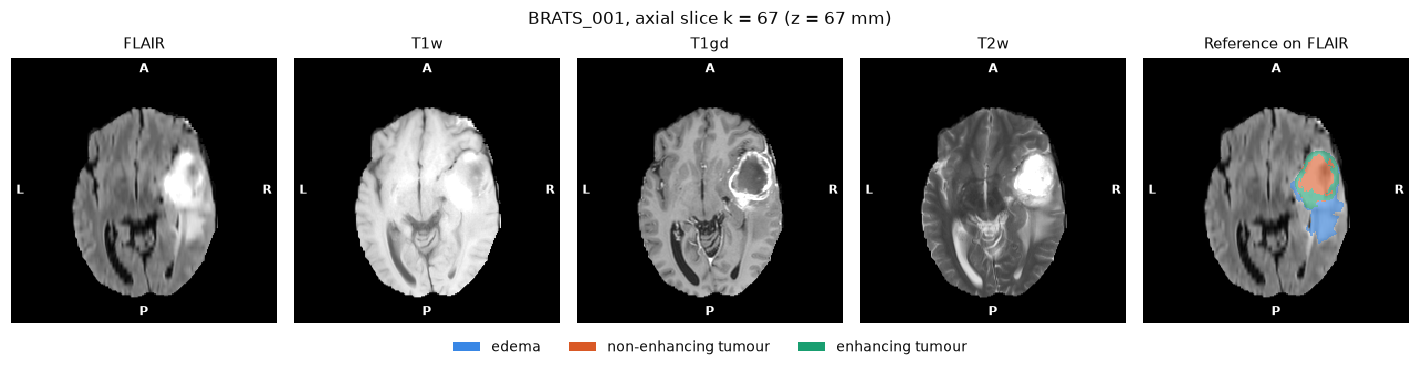

In [3]:
cid = inspect_ids[0]
image, label, affine, spacing = data.load_case(by_id.loc[cid, "image_path"], by_id.loc[cid, "label_path"])
image_ras, sp_ras = viz.to_ras(image, affine)   # identity affine here, so this changes nothing
label_ras, _ = viz.to_ras(label, affine)
brain = data.brain_mask(image_ras)
ci, cj, ck = viz.centre_of_mass(label_ras > 0)
world = affine @ np.array([ci, cj, ck, 1.0])
print(f"{cid}: tumour centre of mass at voxel (i, j, k) = ({ci}, {cj}, {ck}) "
      f"-> world (x, y, z) = ({world[0]:.0f}, {world[1]:.0f}, {world[2]:.0f}) mm")

fig, axes = plt.subplots(1, 5, figsize=(13, 3.2))
for c, ax in enumerate(axes[:4]):
    lo, hi = viz.display_range(image_ras[c], brain)
    viz.show_plane(ax, image_ras[c], "axial", ck, sp_ras, vmin=lo, vmax=hi, title=CHANNELS[c])
lo, hi = viz.display_range(image_ras[0], brain)
viz.show_plane(axes[4], image_ras[0], "axial", ck, sp_ras, overlay=viz.label_overlay(label_ras), vmin=lo, vmax=hi,
               title="Reference on FLAIR")
fig.legend(handles=viz.legend_patches(viz.LABEL_COLOURS, data.LABEL_NAMES), loc="lower center", ncol=3)
fig.suptitle(f"{cid}, axial slice k = {ck} (z = {world[2]:.0f} mm)", y=1.0)
plt.tight_layout(rect=(0, 0.07, 1, 1))
save(fig, "fig_modalities")
plt.show()

### 1.3 Reference in three planes, and why index order is not enough

Top row: the raw array displayed in file-index order with matplotlib defaults (`imshow(vol[:, :, k])`). Bottom row: the same voxels reoriented with the affine (`to_ras`), transposed so the horizontal and vertical screen axes are anatomical axes, displayed with `origin="lower"` and an aspect ratio from the voxel spacing.

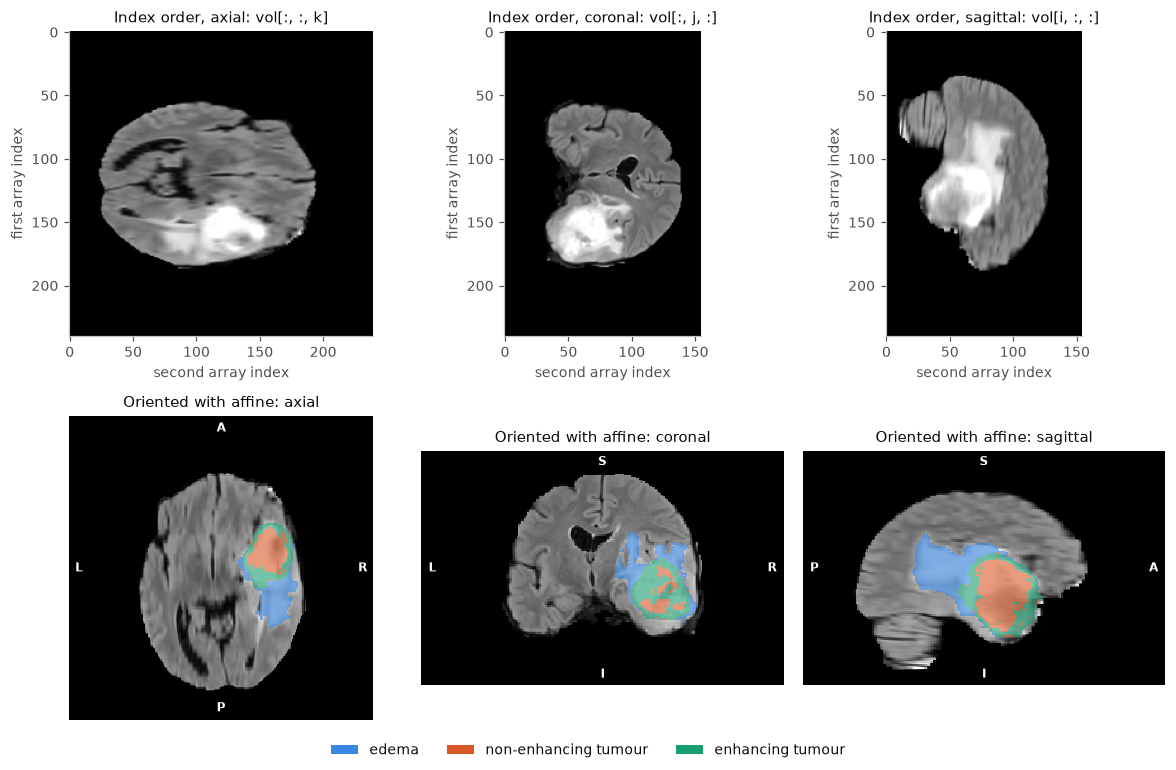

Header orientation codes: RAS | spacing (mm): (1.0, 1.0, 1.0)


In [4]:
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
naive = [("axial: vol[:, :, k]", image[0][:, :, ck]), ("coronal: vol[:, j, :]", image[0][:, cj, :]),
         ("sagittal: vol[i, :, :]", image[0][ci, :, :])]
for ax, (title, sl) in zip(axes[0], naive):
    ax.imshow(sl, cmap="gray", vmin=lo, vmax=hi)
    ax.set_title(f"Index order, {title}")
    ax.set_xlabel("second array index"), ax.set_ylabel("first array index"), ax.grid(False)
overlay = viz.label_overlay(label_ras)
for ax, plane, idx in zip(axes[1], ["axial", "coronal", "sagittal"], [ck, cj, ci]):
    viz.show_plane(ax, image_ras[0], plane, idx, sp_ras, overlay=overlay, vmin=lo, vmax=hi,
                   title=f"Oriented with affine: {plane}")
fig.legend(handles=viz.legend_patches(viz.LABEL_COLOURS, data.LABEL_NAMES), loc="lower center", ncol=3)
plt.tight_layout(rect=(0, 0.04, 1, 1))
save(fig, "fig_planes")
plt.show()
print("Header orientation codes:", "".join(nib.aff2axcodes(affine)), "| spacing (mm):", spacing)

**Why file-index order alone is insufficient.** A NIfTI array is just a 3D grid; which anatomical direction each index runs along, and how far apart voxels are, is stored separately in the affine. Displaying the indices directly (top row) puts the first index on the screen's vertical axis with the origin at the top, so every plane appears rotated by 90° and the sagittal view has the head lying on its side. Nothing in the array says which side is anterior, superior or left. Reading the affine (here the identity: index *i* runs towards patient right, *j* towards anterior, *k* towards superior, 1 mm apart) is what gives the bottom row its correct anatomical layout, and the same procedure works for files stored in other orientations (for example LPS, or oblique acquisitions) where a fixed transpose would silently mirror or rotate the anatomy. The spacing matters too: with anisotropic voxels the image must be drawn with the right aspect ratio and any distance or volume must be multiplied by the voxel size, not counted in voxels. Finally, "slice 77" is not a location; only world coordinates (mm) from the affine allow positions to be compared across channels, cases or scanners.

The anatomy confirms the header's anterior and superior directions (in the sagittal view the cerebellum sits at low *j* and low *k*). The left–right direction cannot be verified from image content because the brain is nearly symmetric, so the L/R labels in the figures come from the header alone and no laterality claims are made.

## 2. Reproducible case-level split

The supplied `assignment2_split.csv` is used exactly as provided. No slice- or patch-level split is created; patches are drawn on the fly from training cases only.

In [5]:
# Setup check from the assignment brief
split_check = pd.read_csv(SPLIT_FILE)
assert len(split_check) == 484
assert set(split_check["split"]) == {"train", "validation", "test"}
for row in split_check.itertuples():
    assert (DATA_ROOT / row.image_relpath).exists()
    assert (DATA_ROOT / row.label_relpath).exists()
print(split_check["split"].value_counts())

split
train         338
test           73
validation     73
Name: count, dtype: int64


In [6]:
ids = {s: set(g["case_id"]) for s, g in split_df.groupby("split")}
assert split_df["case_id"].is_unique, "duplicate case_id"
for a, b in combinations(ids, 2):
    assert not ids[a] & ids[b], f"{a} and {b} share cases"
# Each row's image and label file belong to that row's case
assert all(Path(p).name == f"{c}.nii.gz" for c, p in zip(split_df.case_id, split_df.image_relpath))
assert all(Path(p).name == f"{c}.nii.gz" for c, p in zip(split_df.case_id, split_df.label_relpath))
# Every labelled case in the archive is in the split exactly once
archive_ids = {p.name.removesuffix(".nii.gz") for p in (DATA_ROOT / "imagesTr").glob("BRATS_*.nii.gz")}
assert archive_ids == set(split_df.case_id)
print("All 484 images and labels exist; case IDs are unique and disjoint across",
      ", ".join(f"{s} ({len(v)})" for s, v in ids.items()))

train_ids = split_df.loc[split_df.split == "train", "case_id"].tolist()
val_ids = split_df.loc[split_df.split == "validation", "case_id"].tolist()
test_ids = split_df.loc[split_df.split == "test", "case_id"].tolist()

All 484 images and labels exist; case IDs are unique and disjoint across test (73), train (338), validation (73)


**Reference tumour volume per split.** Computed once from the label files as whole-tumour voxels × voxel volume. This is a descriptive table required by the brief; the test labels are read here and when the cache is built, but no setting, threshold, model or postprocessing rule is chosen using them. They are next used in Section 6.

,cases,mean,std,min,25%,50%,75%,max
split,,,,,,,,
train,338.0,103.0,57.0,8.5,60.0,95.5,143.9,265.3
validation,73.0,100.8,63.0,7.3,51.9,91.6,148.1,266.9
test,73.0,107.4,66.3,10.1,54.4,89.1,157.7,318.3


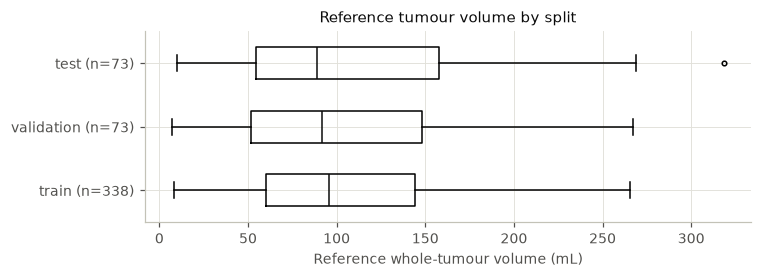

In [7]:
def whole_tumour_ml(label_path):
    lb = nib.load(label_path)
    return np.count_nonzero(np.asarray(lb.dataobj)) * voxel_volume_ml(lb.header.get_zooms()[:3])

split_df["ref_volume_ml"] = [whole_tumour_ml(p) for p in split_df.label_path]
vol_table = split_df.groupby("split")["ref_volume_ml"].describe(percentiles=[0.25, 0.5, 0.75])
vol_table = vol_table.loc[["train", "validation", "test"]].rename(columns={"count": "cases"})
display(vol_table.round(1))

fig, ax = plt.subplots(figsize=(7, 2.6))
order = ["train", "validation", "test"]
ax.boxplot([split_df.loc[split_df.split == s, "ref_volume_ml"] for s in order], orientation="horizontal", widths=0.5,
           medianprops=dict(color=viz.INK), flierprops=dict(markersize=3))
ax.set_yticks([1, 2, 3], [f"{s} (n={len(ids[s])})" for s in order])
ax.set_xlabel("Reference whole-tumour volume (mL)")
ax.set_title("Reference tumour volume by split")
plt.tight_layout(); save(fig, "fig_split_volumes"); plt.show()

### 2.1 Hidden overlap: near-duplicate scans across splits

Disjoint case IDs do not guarantee disjoint patients or scans. MSD Task01 is derived from BraTS 2016 and 2017, so the same acquisition could appear under two IDs. Each scan is reduced to a coarse fingerprint (FLAIR and T2w, each z-scored within the brain, downsampled about 10× and z-scored again, so independent of intensity scaling; `data.scan_fingerprint`) and all 117,000 pairs of cases are compared by correlation. A clear gap between the near-duplicate pairs and every other pair shows that the threshold (0.99) is not arbitrary.

In [8]:
dup_pairs, next_r = data.near_duplicate_pairs(split_df)
split_of = by_id["split"]
dup_pairs["splits"] = [" / ".join(sorted((split_of[a], split_of[b]))) for a, b in zip(dup_pairs.case_a, dup_pairs.case_b)]
n_cases = dup_pairs[["case_a", "case_b"]].stack().nunique()
print(f"{len(dup_pairs)} near-duplicate pairs (correlation > 0.99, lowest {dup_pairs.r.min():.4f}); "
      f"highest correlation among all other pairs: {next_r:.4f}")
print(f"{n_cases} cases involved, each in one pair -> {len(split_df) - len(dup_pairs)} distinct scans among {len(split_df)} case IDs")
display(dup_pairs.splits.value_counts().rename("pairs").to_frame().T)

partner = {**dict(zip(dup_pairs.case_a, dup_pairs.case_b)), **dict(zip(dup_pairs.case_b, dup_pairs.case_a))}
test_with_twin = [c for c in test_ids if c in partner and split_of[partner[c]] in ("train", "validation")]
val_with_twin = [c for c in val_ids if c in partner and split_of[partner[c]] == "train"]
print(f"Test cases with a near-duplicate in train or validation: {len(test_with_twin)} of {len(test_ids)}")
print(f"Validation cases with a near-duplicate in train:         {len(val_with_twin)} of {len(val_ids)}")

# How similar are the two reference annotations of the same scan?
def wt(cid):
    return np.asarray(nib.load(by_id.loc[cid, "label_path"]).dataobj) > 0
ann = []
for a, b in zip(dup_pairs.case_a, dup_pairs.case_b):
    la, lb = wt(a), wt(b)
    ann.append(2 * np.count_nonzero(la & lb) / (np.count_nonzero(la) + np.count_nonzero(lb)))
dup_pairs["label_dice"] = ann
print(f"Whole-tumour Dice between the two annotations of the same scan: mean {np.mean(ann):.3f}, "
      f"median {np.median(ann):.3f}, min {np.min(ann):.3f}; identical label files: {int(np.sum(np.array(ann) == 1))}")
dup_pairs.to_csv(RESULTS_DIR / "near_duplicate_pairs.csv", index=False)

116 near-duplicate pairs (correlation > 0.99, lowest 0.9998); highest correlation among all other pairs: 0.9619
232 cases involved, each in one pair -> 368 distinct scans among 484 case IDs


splits,train / train,train / validation,test / train,test / validation,test / test,validation / validation
pairs,57,26,23,6,3,1


Test cases with a near-duplicate in train or validation: 29 of 73
Validation cases with a near-duplicate in train:         26 of 73


Whole-tumour Dice between the two annotations of the same scan: mean 0.922, median 0.932, min 0.649; identical label files: 6


**Consequence.** Case IDs are disjoint, but 116 scans appear twice; in each pair the lower ID (1–274) and the higher ID (275–479) carry the same images, and in 110 of the 116 pairs a *different* reference annotation (whole-tumour agreement between the two versions: mean Dice 0.92). The split is used exactly as supplied, as the brief requires, but this is case-level, not scan-level, separation: 29 of the 73 test cases (and 26 of the 73 validation cases) have a twin scan the model was trained on or was selected with. Three consequences are carried through the analysis: (1) Section 6.5 tests whether cases with a twin score higher *because* the model saw the scan (it finds no evidence of that: the gap is case mix); (2) validation has the same structure (26 cases with a training twin), shared equally by both samplers, so the controlled comparison in Section 5 is unaffected; (3) the 0.92 agreement between two annotations of the same images is a rough ceiling for any automatic method scored against one of them.

## 3. Safe preprocessing

### 3.1 Geometry of all channels and labels

Read from the NIfTI headers of all 484 cases. The four channels share one 4D header, so they share one affine by construction; the label is a separate file and must match that grid. As a stronger check that the channels were skull-stripped identically, each channel's non-zero region is compared with the brain mask (voxels non-zero in any channel).

The same cell builds the preprocessing cache (Sections 3.3–3.4) once: geometry check, per-channel normalisation, crop to the brain bounding box, float16 arrays in `cache/`.

In [9]:
geo = pd.DataFrame([{"case_id": r.case_id, **data.header_geometry(r.image_path, r.label_path)}
                    for r in split_df.itertuples()])
ref_affine = geo.affine.iloc[0]
geo["affine_same_as_first"] = [np.allclose(a, ref_affine) for a in geo.affine]
for col in ["image_shape", "label_shape", "spacing", "label_spacing", "axcodes", "label_axcodes",
            "affines_match", "affine_same_as_first", "image_dtype"]:
    print(f"{col:22s}", geo[col].astype(str).value_counts().to_dict())

t0 = time.time()
meta_df = data.preprocess_all(split_df, CACHE_DIR, workers=8)
meta = meta_df.set_index("case_id").to_dict("index")
print(f"\nCache ready for {len(meta_df)} cases ({time.time() - t0:.0f} s). Resampled: {int(meta_df.resampled.sum())}; "
      f"tumour voxels outside the brain crop: {int(meta_df.tumour_outside_box.sum())}")

zero_frac = np.array(meta_df.channel_zero_in_brain.tolist()) / meta_df.brain_voxels.to_numpy()[:, None]
agree = pd.DataFrame(zero_frac * 100, columns=CHANNELS).describe(percentiles=[0.5, 0.95]).loc[["mean", "50%", "95%", "max"]]
print("\nBrain voxels (non-zero in any channel) that are zero in this channel, % of brain, over 484 cases:")
display(agree.round(2))
worst = meta_df.case_id[zero_frac.max(1).argmax()]
print(f"Largest: {worst}, {CHANNELS[zero_frac.max(0).argmax()]} zero in {zero_frac.max():.1%} of its brain voxels")

# Where do the disagreeing voxels lie? Distance from the brain surface, for the inspected cases
for case_id in inspect_ids:
    img, _, _, _ = data.load_case(by_id.loc[case_id, "image_path"], by_id.loc[case_id, "label_path"])
    nz = img != 0
    disagree = nz.any(0) & ~nz.all(0)
    depth = ndimage.distance_transform_edt(nz.any(0))[disagree]
    print(f"{case_id}: {disagree.sum() / nz.any(0).sum():.2%} of brain voxels are zero in at least one channel; "
          f"median depth below the brain surface {np.median(depth):.1f} mm")

image_shape            {'(240, 240, 155, 4)': 484}
label_shape            {'(240, 240, 155)': 484}
spacing                {'(1.0, 1.0, 1.0)': 484}
label_spacing          {'(1.0, 1.0, 1.0)': 484}
axcodes                {'RAS': 484}
label_axcodes          {'RAS': 484}
affines_match          {'True': 484}
affine_same_as_first   {'True': 484}
image_dtype            {'float32': 484}

Cache ready for 484 cases (0 s). Resampled: 0; tumour voxels outside the brain crop: 0

Brain voxels (non-zero in any channel) that are zero in this channel, % of brain, over 484 cases:


,FLAIR,T1w,T1gd,T2w
mean,0.51,0.23,0.12,0.09
50%,0.00,0.00,0.00,0.00
95%,0.93,0.62,0.62,0.54
max,50.21,32.90,9.50,3.25


Largest: BRATS_025, FLAIR zero in 50.2% of its brain voxels


BRATS_001: 0.93% of brain voxels are zero in at least one channel; median depth below the brain surface 1.0 mm


BRATS_003: 5.03% of brain voxels are zero in at least one channel; median depth below the brain surface 2.4 mm


BRATS_004: 0.76% of brain voxels are zero in at least one channel; median depth below the brain surface 1.0 mm


The channels agree except at the margin: for most cases the disagreement is a one-voxel rim at the brain surface, where each channel's skull-stripping boundary differs slightly. A few cases have a larger region missing in one channel (a smaller field of view in that acquisition). This matters for normalisation (Section 3.3).

**Target grid.** Every case is already on one common grid: 240 × 240 × 155 voxels, 1 mm isotropic, identity affine (RAS), with image and label affines equal. That grid is the target, so no resampling is applied. `data.preprocess_case` still checks each case and would resample to 1 mm (linear for MRI, nearest neighbour for labels) if a case had different spacing; the `resampled` flag in the cache metadata records that it never did.

### 3.2 Interpolation: linear for MRI, nearest neighbour for labels

Demonstrated by resampling one case to a 2 mm grid. Labels are categorical codes, not quantities: linear interpolation between label 1 (edema) and 3 (enhancing tumour) produces 2 (non-enhancing tumour) or fractional values that are not classes at all.

Original label values:          [0, 1, 2, 3]  grid (240, 240, 155)
Nearest neighbour (order 0):    [0, 1, 2, 3]  grid (120, 120, 78)
Linear (order 1):               1970 distinct values, e.g. [1.0199999809265137, 1.3300000429153442, 1.649999976158142, 1.9600000381469727, 2.2899999618530273, 2.569999933242798] ...
Linear: 26.6% of non-zero label voxels are non-integer
Whole-tumour volume: original 111.7 mL, nearest-neighbour 2 mm 110.0 mL
MRI resampled linearly to (4, 120, 120, 78); FLAIR range 0-1726 (original 0-1829; linear interpolation cannot overshoot)


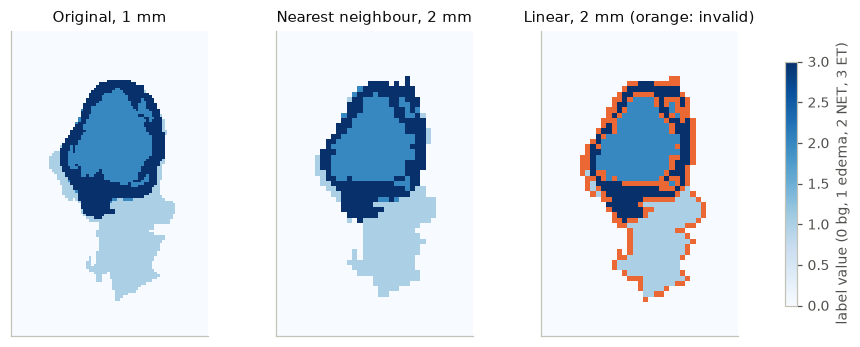

In [10]:
img_2mm, lbl_nn = data.resample(image, label, spacing, target=(2.0, 2.0, 2.0))
lbl_lin = ndimage.zoom(label.astype(np.float32), 0.5, order=1)
print(f"Original label values:          {np.unique(label).tolist()}  grid {label.shape}")
print(f"Nearest neighbour (order 0):    {np.unique(lbl_nn).tolist()}  grid {lbl_nn.shape}")
lin_vals = np.unique(lbl_lin)
between = np.unique(np.round(lbl_lin[(lbl_lin > 1) & (lbl_lin < 3) & (lbl_lin != 2)], 2))
print(f"Linear (order 1):               {len(lin_vals)} distinct values, e.g. {between[::len(between) // 6][:6].tolist()} ...")
in_tumour = lbl_lin > 0
print(f"Linear: {np.mean(lbl_lin[in_tumour] != np.round(lbl_lin[in_tumour])):.1%} of non-zero label voxels are non-integer")
print(f"Whole-tumour volume: original {np.count_nonzero(label) * 1e-3:.1f} mL, "
      f"nearest-neighbour 2 mm {np.count_nonzero(lbl_nn) * 8e-3:.1f} mL")
print(f"MRI resampled linearly to {img_2mm.shape}; FLAIR range {img_2mm[0].min():.0f}-{img_2mm[0].max():.0f} "
      f"(original {image[0].min():.0f}-{image[0].max():.0f}; linear interpolation cannot overshoot)")

# Zoom on the tumour; mm extents so 1 mm and 2 mm grids line up
(i0, j0, _), (i1, j1, _) = data.bounding_box(label > 0)
win = (i0 - 10, i1 + 10, j0 - 10, j1 + 10)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, (title, vol, mm) in zip(axes, [("Original, 1 mm", label, 1), ("Nearest neighbour, 2 mm", lbl_nn, 2),
                                        ("Linear, 2 mm", lbl_lin, 2)]):
    sl = viz.plane_slice(vol, "axial", ck // mm)
    extent = (-0.5 * mm, (sl.shape[1] - 0.5) * mm, -0.5 * mm, (sl.shape[0] - 0.5) * mm)
    im_ = ax.imshow(sl, cmap="Blues", origin="lower", vmin=0, vmax=3, interpolation="nearest", extent=extent)
    if mm == 2 and vol.dtype != np.uint8:
        bad = (sl != np.round(sl)).astype(float)
        ax.imshow(np.ma.masked_equal(bad, 0), cmap=plt.matplotlib.colors.ListedColormap([viz.SAMPLER_COLOURS["tumour"]]),
                  origin="lower", extent=extent, interpolation="nearest")
        title += " (orange: invalid)"
    ax.set_xlim(win[0], win[1]), ax.set_ylim(win[2], win[3])
    ax.set_title(title), ax.set_xticks([]), ax.set_yticks([]), ax.grid(False)
fig.colorbar(im_, ax=axes, shrink=0.8, label="label value (0 bg, 1 edema, 2 NET, 3 ET)")
save(fig, "fig_interpolation")
plt.show()

### 3.3 Intensity normalisation on brain voxels

MRI intensities have no absolute scale: the same tissue has different raw values across scanners and cases. Each channel of each case is z-scored using the mean and standard deviation of that channel's **non-zero (brain) voxels** only; zeros stay exactly 0. Including the zero background, about 83 % of the volume, would drag the mean towards 0 and inflate the standard deviation by an amount that depends on head size rather than tissue contrast (compare the "all voxels" and "brain" columns below).

The mask is per channel because of the margin differences found in Section 3.1. With one shared brain mask, a voxel that is zero in one channel but not in the others would be normalised to (0 − mean)/SD ≈ −3, an artificial dark value the network could learn from; with per-channel masks it stays at 0, which after z-scoring is that channel's mean brain intensity.


BRATS_001:


,raw mean (all voxels),raw SD (all voxels),raw mean (brain),raw SD (brain),normalised mean (brain),normalised SD (brain),normalised min,normalised max
channel,,,,,,,,
FLAIR,86.021,210.889,516.274,211.648,0.0,1.0,-2.436,6.203
T1w,130.183,302.974,780.635,206.554,-0.0,1.0,-3.769,6.652
T1gd,121.466,288.591,728.439,239.416,-0.0,1.0,-3.039,6.309
T2w,78.686,195.858,471.844,211.000,-0.0,1.0,-2.232,5.672


All 484 cases x 4 channels, non-zero voxels after normalisation (float16 cache): mean in [-0.0001, 0.0001], SD in [0.9999, 1.0002]


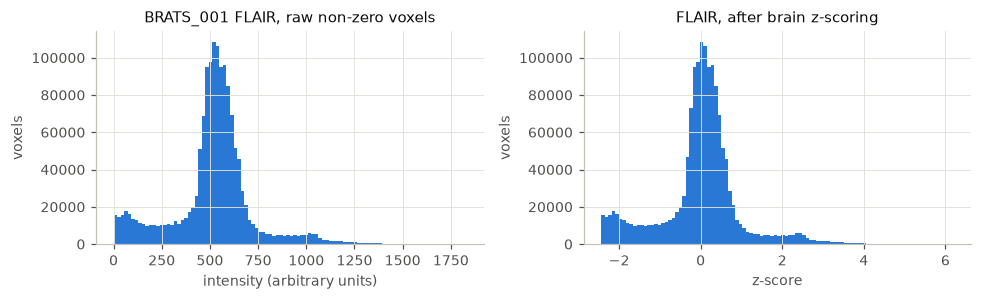

In [11]:
# Before/after statistics for the inspected case
img_all = image.reshape(4, -1)
img_c, _ = data.load_cached(CACHE_DIR, cid)
stats_rows = []
for c, name in enumerate(CHANNELS):
    m = meta[cid]
    stats_rows.append({"channel": name,
                       "raw mean (all voxels)": img_all[c].mean(), "raw SD (all voxels)": img_all[c].std(),
                       "raw mean (brain)": m["raw_mean"][c], "raw SD (brain)": m["raw_std"][c],
                       "normalised mean (brain)": m["norm_mean"][c], "normalised SD (brain)": m["norm_std"][c],
                       "normalised min": float(np.asarray(img_c[c]).min()), "normalised max": float(np.asarray(img_c[c]).max())})
print(f"\n{cid}:")
display(pd.DataFrame(stats_rows).set_index("channel").round(4))

nm, ns = np.array(meta_df.norm_mean.tolist()), np.array(meta_df.norm_std.tolist())
print(f"All 484 cases x 4 channels, non-zero voxels after normalisation (float16 cache): "
      f"mean in [{nm.min():.4f}, {nm.max():.4f}], SD in [{ns.min():.4f}, {ns.max():.4f}]")

fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
axes[0].hist(image[0][image[0] != 0], bins=100, color=viz.SAMPLER_COLOURS["uniform"])
axes[0].set_title(f"{cid} FLAIR, raw non-zero voxels"), axes[0].set_xlabel("intensity (arbitrary units)")
vals = np.asarray(img_c[0], dtype=np.float32)
axes[1].hist(vals[vals != 0], bins=100, color=viz.SAMPLER_COLOURS["uniform"])
axes[1].set_title("FLAIR, after brain z-scoring"), axes[1].set_xlabel("z-score")
for ax in axes: ax.set_ylabel("voxels")
plt.tight_layout(); plt.show()

### 3.4 Cropping, padding and training-only augmentation

**Crop.** Each case is cropped to the bounding box of its brain mask, removing all-zero margins while keeping every brain (and every tumour) voxel; the box is stored so predictions can be pasted back into the original 240 × 240 × 155 grid with the original affine. **Pad.** A crop smaller than the patch along any axis would be zero-padded (to the patch size for training, by the sliding window at inference); with 64³ patches and crops of at least 119 voxels per axis this never triggers.

**Augmentation (training only).** Validation and test volumes are never augmented. Two transforms are used, applied identically to image and mask:
1. *Left–right flip* (p = 0.5) along axis *i*. Brains are roughly mirror-symmetric and gliomas occur in either hemisphere, so a flipped case is a plausible case; anterior–posterior or superior–inferior flips would produce anatomy that never occurs and are not used. The mask is flipped with the image, so labels stay aligned and binary (no interpolation).
2. *Per-channel intensity scale* (×0.9–1.1) *and shift* (±0.1 SD) on brain voxels only. This imitates residual contrast differences between scanners that z-scoring does not remove, without changing geometry. Background stays 0.

Rotations, elastic deformation and rescaling were not used: they require 3D interpolation per patch (slow on CPU workers with this budget) and, for the label, nearest-neighbour resampling at every step.

Brain-crop shape over 484 cases: min [122 144 119], median [138 169 138], max [160 187 149]
Voxels kept by the crop: median 36.2% of the original grid


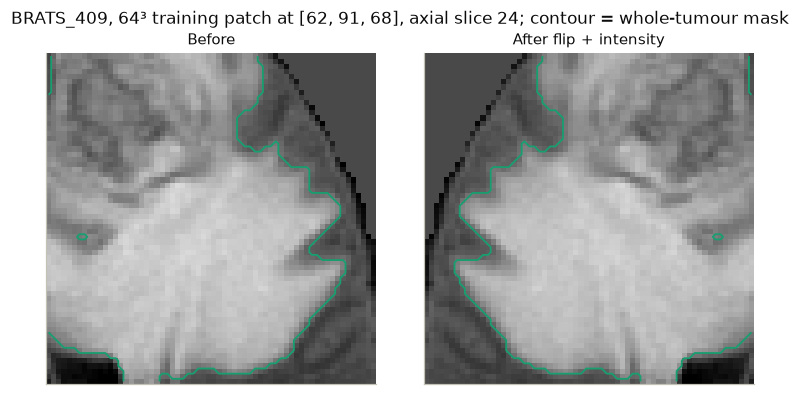

Channel mean on brain voxels before: [ 1.567 -0.01   0.432  1.055] after: [ 1.549 -0.073  0.308  1.032]
Mask values after augmentation: [0.0, 1.0] | tumour voxels before/after: 129869 129869


In [12]:
crop = np.array(meta_df.crop_shape.tolist())
print(f"Brain-crop shape over 484 cases: min {crop.min(0)}, median {np.median(crop, 0).astype(int)}, max {crop.max(0)}")
print(f"Voxels kept by the crop: median {np.median(crop.prod(1) / (240 * 240 * 155)):.1%} of the original grid")

# One paired before/after example on a real training patch centred on tumour
demo = PatchDataset(CACHE_DIR, train_ids, 64, 10, sampler="tumour", fg_prob=1.0, seed=SEED, train_augment=False)
case_demo, start, _, _ = demo.location(3)
x_before, y_before = (t.numpy() for t in demo[3])
# Seed picked so that this example's first draw triggers the flip, making both transforms visible
aug_seed = next(s for s in range(100) if np.random.default_rng(s).random() < 0.5)
rng = np.random.default_rng(aug_seed)
x_after, y_after = augment(x_before.copy(), y_before[0].copy(), rng)
s = int(np.argmax(y_before[0].sum((0, 1))))
fig, axes = plt.subplots(1, 2, figsize=(7, 3.6))
for ax, (title, x, y) in zip(axes, [("Before", x_before, y_before[0]), ("After flip + intensity", x_after, y_after)]):
    ax.imshow(x[0][:, :, s].T, cmap="gray", origin="lower", vmin=-2, vmax=5)
    ax.contour(y[:, :, s].T, levels=[0.5], colors=[viz.ERROR_COLOURS["TP"]], linewidths=1.2)
    ax.set_title(title), ax.set_xticks([]), ax.set_yticks([]), ax.grid(False)
fig.suptitle(f"{case_demo}, 64³ training patch at {start.tolist()}, axial slice {s}; contour = whole-tumour mask")
plt.tight_layout(); save(fig, "fig_augmentation"); plt.show()
brain_p = x_before[0] != 0
print("Channel mean on brain voxels before:", np.round(x_before[:, brain_p].mean(1), 3),
      "after:", np.round(x_after[:, x_after[0] != 0].mean(1), 3))
print("Mask values after augmentation:", np.unique(y_after).tolist(),
      "| tumour voxels before/after:", int(y_before.sum()), int(y_after.sum()))

## 4. Patch-based volumetric training

### 4.1 Dataset and DataLoader

`PatchDataset` cuts 64³ patches from the cached, brain-cropped volumes (memory-mapped, so only the patch is read). Each item is generated from its own RNG seeded with `(seed, index)`, so the patch stream is identical for any number of DataLoader workers.

In [13]:
cfg_u, cfg_t = EXPERIMENTS["uniform"], EXPERIMENTS["tumour"]
demo_ds = PatchDataset(CACHE_DIR, train_ids, cfg_t.patch, 64, cfg_t.sampler, cfg_t.fg_prob, seed=SEED, train_augment=True)
x0, y0 = demo_ds[0]
print("One item:  image", tuple(x0.shape), x0.dtype, "| mask", tuple(y0.shape), y0.dtype)
xb, yb = next(iter(DataLoader(demo_ds, batch_size=cfg_t.batch_size, num_workers=0)))
print("One batch: image", tuple(xb.shape), xb.dtype, "| mask", tuple(yb.shape), yb.dtype)
print("Mask values:", torch.unique(yb).tolist(), "| tumour voxels per patch:", yb.sum((1, 2, 3, 4)).int().tolist())
print("Per-channel mean / SD in the batch:", [f"{CHANNELS[c]} {xb[:, c].mean():.2f}/{xb[:, c].std():.2f}" for c in range(4)])
assert xb.shape[1:] == (4, 64, 64, 64) and yb.shape[1:] == (1, 64, 64, 64)
assert set(torch.unique(yb).tolist()) <= {0.0, 1.0}

One item:  image (4, 64, 64, 64) torch.float32 | mask (1, 64, 64, 64) torch.float32
One batch: image (4, 4, 64, 64, 64) torch.float32 | mask (4, 1, 64, 64, 64) torch.float32
Mask values: [0.0, 1.0] | tumour voxels per patch: [5345, 18306, 76186, 129869]
Per-channel mean / SD in the batch: ['FLAIR 0.46/1.08', 'T1w 0.05/0.75', 'T1gd 0.17/1.08', 'T2w 0.36/0.98']


### 4.2 Model

A 3D U-Net with five resolution levels (16, 32, 64, 128, 256 feature maps). Each level has two 3×3×3 convolutions, each followed by instance normalisation and leaky ReLU; max pooling halves the resolution, transposed convolutions double it, and skip connections concatenate encoder features into the decoder. A final 1×1×1 convolution gives one logit per voxel. Instance normalisation is used because the batch holds only four patches, too few for stable batch statistics. The network is fully convolutional, so the same weights apply to any input whose sides are multiples of 16.

In [14]:
model_demo = UNet3D(in_channels=4, out_channels=1, features=cfg_u.features)
with torch.no_grad():
    out = model_demo(torch.zeros(1, 4, cfg_u.patch, cfg_u.patch, cfg_u.patch))
print(f"Input channels: 4 ({', '.join(CHANNELS)}) | output channels: 1 (whole-tumour logit)")
print(f"Parameters: {count_parameters(model_demo):,} | patch: {cfg_u.patch}³ voxels = {cfg_u.patch} mm per side "
      f"| output for one patch: {tuple(out.shape)}")
print("Resolution per level:", " -> ".join(f"{cfg_u.patch // 2**i}³×{f}" for i, f in enumerate(cfg_u.features)))

Input channels: 4 (FLAIR, T1w, T1gd, T2w) | output channels: 1 (whole-tumour logit)
Parameters: 5,647,681 | patch: 64³ voxels = 64 mm per side | output for one patch: (1, 1, 64, 64, 64)
Resolution per level: 64³×16 -> 32³×32 -> 16³×64 -> 8³×128 -> 4³×256


### 4.3 Training configuration and the uniform-sampling run

Both runs share every setting except the sampler (`a2/experiments.py`). The loss is binary cross-entropy plus (1 − soft Dice), with Dice computed over the whole batch so tumour-free patches do not produce 0/0. Cross-entropy gives a well-behaved per-voxel gradient; the Dice term counters the class imbalance (tumour is about 7 % of brain voxels). The learning rate follows a cosine decay from 1e-3 to 0 over the fixed iteration budget, so both runs end at the same point of the schedule and the final weights are compared, not a checkpoint picked per run.

Every 500 iterations the model is evaluated on all 73 validation cases with the same full-volume sliding-window inference used at test time (Section 6.1). The validation loss is the same BCE + Dice loss applied to the blended full-volume probabilities; it is therefore neutral to which sampler was used, unlike a loss on sampled patches.

In [15]:
cfg_table = pd.DataFrame([vars(cfg_u), vars(cfg_t)]).set_index("name").T.astype(str)
cfg_table.loc["loss"] = "BCE + (1 - soft Dice)"
cfg_table.loc["optimiser"] = "AdamW, cosine LR decay to 0"
display(cfg_table)

model_u, hist_u = train(cfg_u, CACHE_DIR, train_ids, val_ids, MODEL_DIR, DEVICE)
print(f"Uniform run: {hist_u['runtime_min']:.0f} min on {hist_u['device']}, init hash {hist_u['init_hash']}")

name,uniform,tumour
sampler,uniform,tumour
fg_prob,0.0,0.5
patch,64,64
batch_size,4,4
iterations,5000,5000
lr,0.001,0.001
weight_decay,0.0001,0.0001
seed,2440,2440
features,"(16, 32, 64, 128, 256)","(16, 32, 64, 128, 256)"
eval_every,500,500


[uniform] reusing saved run from models
Uniform run: 70 min on mps, init hash 3ab1bbaff442


### 4.4 Tumour-aware sampling run and tumour content of the patches

With probability 0.5 the tumour-aware sampler centres the patch on a randomly chosen tumour voxel; otherwise it places it uniformly. Both runs use the same seed, so they start from identical weights (same hash) and visit the same sequence of cases with the same augmentation draws; only where the patch is cut differs.

In [16]:
model_t, hist_t = train(cfg_t, CACHE_DIR, train_ids, val_ids, MODEL_DIR, DEVICE)
print(f"Tumour-aware run: {hist_t['runtime_min']:.0f} min, init hash {hist_t['init_hash']}")
assert hist_u["init_hash"] == hist_t["init_hash"], "runs did not start from the same initialisation"
print("Identical initialisation:", hist_u["init_hash"] == hist_t["init_hash"])

rows = []
for cfg, hist in [(cfg_u, hist_u), (cfg_t, hist_t)]:
    ds = PatchDataset(CACHE_DIR, train_ids, cfg.patch, cfg.iterations * cfg.batch_size, cfg.sampler, cfg.fg_prob, seed=cfg.seed)
    has, frac = tumour_fraction(ds, n=5000)
    rows.append({"run": cfg.name, "patches with any tumour (first 5,000 drawn)": has,
                 "patches with any tumour (whole run, logged)": np.mean(hist["patch_has_tumour"]),
                 "mean tumour fraction of patch voxels": frac})
sampler_table = pd.DataFrame(rows).set_index("run")
display(sampler_table.round(3))

[tumour] reusing saved run from models
Tumour-aware run: 79 min, init hash 3ab1bbaff442
Identical initialisation: True


,"patches with any tumour (first 5,000 drawn)","patches with any tumour (whole run, logged)",mean tumour fraction of patch voxels
run,,,
uniform,0.790,0.787,0.072
tumour,0.901,0.897,0.161


### 4.5 Learning curves

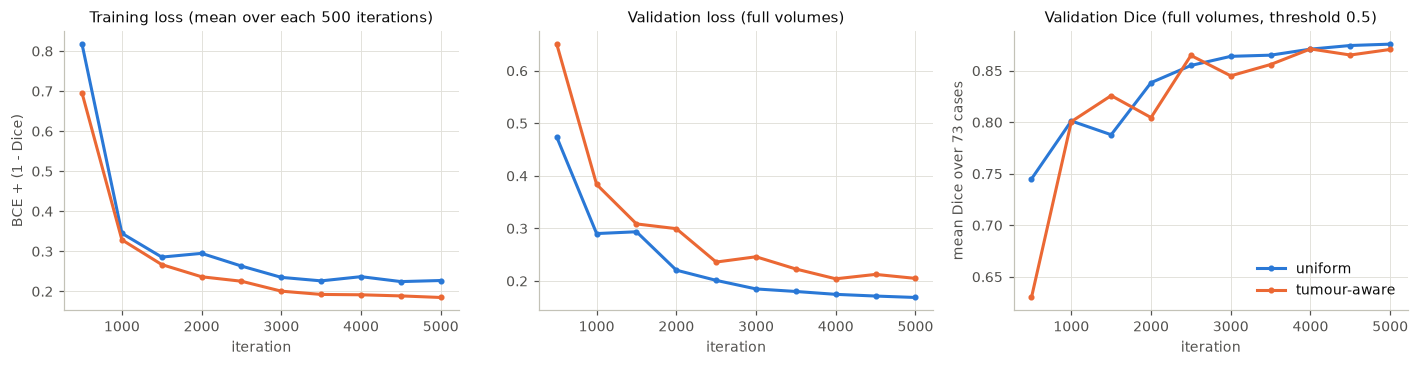

,uniform train_loss,uniform val_loss,uniform val_dice,tumour train_loss,tumour val_loss,tumour val_dice
500,0.817,0.474,0.745,0.695,0.651,0.630
1000,0.345,0.290,0.801,0.329,0.384,0.801
1500,0.286,0.294,0.788,0.267,0.309,0.826
2000,0.295,0.221,0.839,0.236,0.300,0.805
2500,0.263,0.201,0.855,0.225,0.236,0.865
3000,0.235,0.185,0.864,0.201,0.246,0.845
3500,0.226,0.180,0.865,0.192,0.223,0.856
4000,0.237,0.175,0.871,0.192,0.204,0.871
4500,0.225,0.171,0.875,0.189,0.213,0.865
5000,0.227,0.169,0.876,0.185,0.205,0.871


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for name, hist in [("uniform", hist_u), ("tumour", hist_t)]:
    col = viz.SAMPLER_COLOURS[name]
    label = "uniform" if name == "uniform" else "tumour-aware"
    for ax, key in zip(axes, ["train_loss", "val_loss", "val_dice"]):
        ax.plot(hist["iteration"], hist[key], color=col, label=label, marker="o", markersize=3)
axes[0].set_title("Training loss (mean over each 500 iterations)")
axes[1].set_title("Validation loss (full volumes)")
axes[2].set_title("Validation Dice (full volumes, threshold 0.5)")
for ax in axes:
    ax.set_xlabel("iteration")
axes[0].set_ylabel("BCE + (1 - Dice)"), axes[2].set_ylabel("mean Dice over 73 cases")
axes[2].legend(loc="lower right")
plt.tight_layout(); save(fig, "fig_curves"); plt.show()
curve_table = pd.DataFrame({f"{n} {k}": h[k] for n, h in [("uniform", hist_u), ("tumour", hist_t)]
                            for k in ["train_loss", "val_loss", "val_dice"]}, index=hist_u["iteration"])
display(curve_table.round(4))

**Reading the curves.**

- **No overfitting.** Validation loss falls over both runs, with only small bumps (uniform 0.474 → 0.169, tumour-aware 0.651 → 0.205), and validation Dice rises and then levels off around 0.87 from about iteration 3,500 (uniform 0.745 → 0.876, tumour-aware 0.630 → 0.871). There is no point where training loss keeps falling while validation gets worse.
- **Mild underfitting / budget-limited.** The uniform run's validation loss is still decreasing at iteration 5,000 and its last 500 iterations add only +0.001 Dice because the cosine schedule has driven the learning rate to zero, not because the model has converged in any strong sense. A longer schedule or larger model would probably still help a little.
- **Instability.** The tumour-aware run is less stable: its validation Dice drops twice (0.826 → 0.805 at 2,000 and 0.865 → 0.845 at 3,000) while the uniform run rises almost monotonically after 1,500.
- **Training loss is not comparable between runs.** The tumour-aware run has the *lower* training loss but the *higher* validation loss at every checkpoint, because its training patches are a different, more tumour-rich distribution (16 % tumour voxels versus 7 %). Only the full-volume validation curves compare the two on equal terms.

No test data were used for any of these judgements.

## 5. Controlled sampling comparison

Same architecture, initialisation, split, loss, optimiser, schedule, augmentation and budget (5,000 iterations × 4 patches); the only difference is the sampler. Both final models are run over all 73 validation cases with the inference settings of Section 6.1 (64³ windows, 50 % overlap, Gaussian blending, threshold 0.5). False-positive volume is the predicted-tumour volume outside the reference, in mL.

In [18]:
val_results = {}
for name, model in [("uniform", model_u), ("tumour", model_t)]:
    probs, _ = ev.predict_probs(model, CACHE_DIR, val_ids, cfg_u.patch, 0.5, DEVICE, out_dir=PRED_DIR / f"val_{name}")
    val_results[name] = ev.evaluate(probs, CACHE_DIR, meta)
    val_results[name].to_csv(RESULTS_DIR / f"val_metrics_{name}.csv")

cols = ["dice", "sensitivity", "fp_ml", "fn_ml", "hd95_mm", "abs_vol_err_ml"]
comp = pd.concat({n: r[cols].agg(["mean", "median"]).T for n, r in val_results.items()}, axis=1)
diff = val_results["tumour"][cols] - val_results["uniform"][cols]
comp[("tumour - uniform", "mean paired diff")] = diff.mean()
comp[("tumour - uniform", "cases tumour higher")] = (diff > 0).sum()
def wilcoxon_p(a, b):
    d = (a - b).dropna()
    return stats.wilcoxon(d).pvalue if (d != 0).any() else float("nan")
comp[("tumour - uniform", "Wilcoxon p")] = [wilcoxon_p(val_results["tumour"][c], val_results["uniform"][c]) for c in cols]
display(comp.round(4))
print("Empty predictions:", {n: int(r.empty_pred.sum()) for n, r in val_results.items()})

uniform         tumour        tumour - uniform                               
                  mean median    mean median mean paired diff cases tumour higher Wilcoxon p
dice             0.876  0.900   0.871  0.892           -0.005                  38      0.739
sensitivity      0.886  0.910   0.915  0.938            0.029                  60      0.000
fp_ml           10.761  7.600  15.520  9.872            4.759                  53      0.000
fn_ml           10.868  7.567   7.527  5.541           -3.340                  13      0.000
hd95_mm         16.079  6.708  25.565  8.485            9.486                  40      0.007
abs_vol_err_ml  10.269  8.063  11.827  8.496            1.558                  45      0.150

Empty predictions: {'uniform': 0, 'tumour': 0}


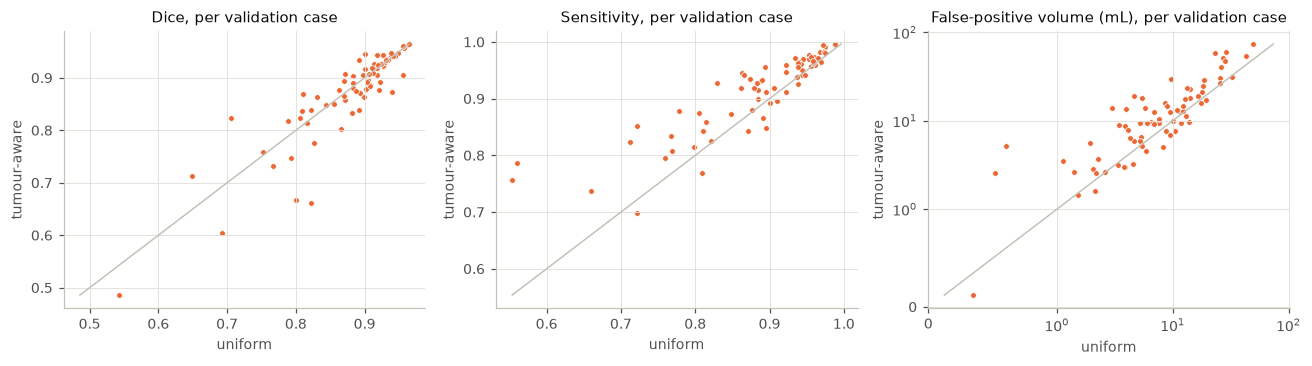

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
u, t = val_results["uniform"], val_results["tumour"]
for ax, col, title in zip(axes, ["dice", "sensitivity", "fp_ml"], ["Dice", "Sensitivity", "False-positive volume (mL)"]):
    lim = [min(u[col].min(), t[col].min()), max(u[col].max(), t[col].max())]
    ax.plot(lim, lim, color=viz.AXIS, linewidth=1)
    ax.scatter(u[col], t[col], s=14, color=viz.SAMPLER_COLOURS["tumour"], edgecolor="white", linewidth=0.5)
    ax.set_xlabel(f"uniform"), ax.set_ylabel("tumour-aware"), ax.set_title(f"{title}, per validation case")
    if col == "fp_ml":
        ax.set_xscale("symlog", linthresh=1), ax.set_yscale("symlog", linthresh=1)
plt.tight_layout(); save(fig, "fig_val_comparison"); plt.show()

**What changed, and why.** The tumour-aware sampler raised the share of patches containing tumour from 79 % to 90 % and more than doubled the tumour fraction of the voxels the network was trained on (7.2 % → 16.1 %). On validation this left Dice unchanged (0.876 vs 0.871; paired difference −0.005, Wilcoxon p = 0.74, tumour-aware better in 38 of 73 cases) but moved the errors:

- sensitivity **rose** from 0.886 to 0.915 (higher in 60 of 73 cases, p < 0.001), and missed tumour volume fell from 10.9 to 7.5 mL;
- false-positive volume **rose** from 10.8 to 15.5 mL (mean; higher in 53 of 73 cases, p < 0.001);
- boundary error rose: median HD95 6.7 → 8.5 mm (p = 0.007).

The mechanism is a shift in the class prior the network learns. With twice as much tumour in its training data, the network's estimate of P(tumour | local appearance) is pushed upwards, so at the fixed 0.5 threshold borderline voxels — the faint outer edge of edema, but also non-tumour tissue that is bright on FLAIR — flip to tumour. The first effect recovers missed tumour (sensitivity up, FN down); the second creates false positives, some of them away from the tumour, which is what drives HD95 up. Dice counts FP and FN together, so the two effects roughly cancel. The higher validation loss of the tumour-aware run (Section 4.5) is the same shift seen through BCE, which penalises confident false positives across the large healthy region.

The difference between the samplers is limited by the data: whole tumours are large here (median about 90 mL, i.e. a sphere of about 55 mm diameter) relative to a 64 mm patch, so even uniform patches inside the brain crop contain tumour 79 % of the time. Oversampling would matter more for small targets such as enhancing tumour alone. The comparison is a single training run per condition, so it cannot separate the sampler effect from run-to-run variation; the paired per-case tests only address variation across cases.

### 5.1 Final configuration (validation evidence only)

Criterion, fixed before the comparison was run: the sampler with the higher mean validation Dice is kept; if the two are within 0.005, the one with the lower median validation HD95 is kept. Threshold (0.5), overlap (50 %) and blending (Gaussian) are fixed and were not tuned.

In [20]:
mean_dice = {n: r.dice.mean() for n, r in val_results.items()}
med_hd = {n: r.hd95_mm.median() for n, r in val_results.items()}
if abs(mean_dice["tumour"] - mean_dice["uniform"]) > 0.005:
    FINAL = max(mean_dice, key=mean_dice.get)
else:
    FINAL = min(med_hd, key=med_hd.get)
final_model = {"uniform": model_u, "tumour": model_t}[FINAL]
print(f"Mean validation Dice {mean_dice}; median validation HD95 {med_hd}")
print(f"Final configuration: {FINAL} sampler")

Mean validation Dice {'uniform': np.float64(0.8758665461966088), 'tumour': np.float64(0.8707188883004069)}; median validation HD95 {'uniform': np.float64(6.708203932499369), 'tumour': np.float64(8.48528137423857)}
Final configuration: uniform sampler


**Selected: uniform sampling.** The rule fixed beforehand picks the higher mean validation Dice (0.8759 vs 0.8707; the 0.0051 gap is only just above the 0.005 tie margin). The tie-break criterion, median validation HD95, also favours uniform (6.7 vs 8.5 mm), and so do false-positive volume and validation loss, so the choice does not hinge on the margin. Tumour-aware sampling would be preferred only if missed tumour were judged much more costly than false-positive tissue, which is a clinical rather than a technical decision.

**A disadvantage of excessive tumour oversampling:** the network sees too little tumour-free tissue, so its probabilities become biased towards tumour and it labels healthy structures that resemble tumour (FLAIR-bright tissue, vessels, artefacts) as tumour. Here even a moderate 50 % centring probability increased mean false-positive volume by 44 % and worsened HD95; pushed towards 100 %, almost every patch would be centred on tumour and the model would rarely learn what normal brain looks like at all.

### 5.2 Connected-component postprocessing rule (chosen on validation)

**Rule:** remove every 26-connected predicted component smaller than *T* mL. A glioma's whole-tumour region (edema plus core) is normally one large contiguous region, so small isolated predicted islands far from it are more likely false positives (for example bright vessels, choroid plexus or artefacts that resemble edema on FLAIR) than real tumour, and they hurt the boundary metric disproportionately. A size threshold is preferred to "keep only the largest component", which would delete genuine separate lesions in multifocal disease.

*T* is chosen from {0.05, 0.1, 0.25, 0.5, 1, 2} mL on the validation predictions of the final model: the lowest median HD95 among thresholds that do not lower mean validation Dice by more than 0.001. If none improves median HD95, no postprocessing is used. The test split is not looked at.

In [21]:
val_probs, _ = ev.predict_probs(final_model, CACHE_DIR, val_ids, cfg_u.patch, 0.5, DEVICE, out_dir=PRED_DIR / f"val_{FINAL}")
pp_rows = [{"T_ml": "none", **val_results[FINAL][["dice", "hd95_mm"]].agg(["mean", "median"]).unstack().to_dict()}]
for T in [0.05, 0.1, 0.25, 0.5, 1.0, 2.0]:
    r = ev.evaluate(val_probs, CACHE_DIR, meta, min_component_ml=T)
    pp_rows.append({"T_ml": str(T), **r[["dice", "hd95_mm"]].agg(["mean", "median"]).unstack().to_dict()})
pp = pd.DataFrame(pp_rows).set_index("T_ml")
pp.columns = [f"{m} {s}" for m, s in pp.columns]
display(pp.round(4))

base = pp.iloc[0]
ok = pp.iloc[1:][(pp.iloc[1:]["dice mean"] >= base["dice mean"] - 0.001) & (pp.iloc[1:]["hd95_mm median"] < base["hd95_mm median"])]
MIN_COMPONENT_ML = float(ok["hd95_mm median"].idxmin()) if len(ok) else None  # index holds the threshold as text
n_comp = [len(ev.component_sizes_ml(p >= 0.5, meta[c]["spacing"])) for c, p in val_probs.items()]
print(f"Predicted components per validation case before postprocessing: median {np.median(n_comp):.0f}, max {max(n_comp)}")
print(f"Chosen rule: remove components < {MIN_COMPONENT_ML} mL" if MIN_COMPONENT_ML else "Chosen rule: none")

,dice mean,dice median,hd95_mm mean,hd95_mm median
T_ml,,,,
none,0.876,0.900,16.079,6.708
0.05,0.876,0.900,16.020,6.708
0.1,0.876,0.900,15.964,6.708
0.25,0.877,0.901,14.614,6.403
0.5,0.877,0.901,13.811,5.827
1.0,0.878,0.901,13.915,5.916
2.0,0.878,0.901,12.140,5.916


Predicted components per validation case before postprocessing: median 4, max 17
Chosen rule: remove components < 0.5 mL


## 6. Full-volume reconstruction and test evaluation

### 6.1 Sliding-window inference

| Setting | Value |
|---|---|
| Patch (window) | 64 × 64 × 64 voxels (64 mm) — the training patch size |
| Overlap / stride | 50 % / 32 voxels along each axis; the last window on each axis is shifted back to end exactly at the volume edge |
| Blending | Each window's sigmoid probabilities are multiplied by a 3D Gaussian weight (σ = 8 voxels, peak 1 at the window centre) and accumulated; the voxel's probability is the weighted sum divided by the summed weights. Probabilities are therefore combined **before** thresholding. |
| Threshold | 0.5 on the blended probability |
| Output | Mask on the brain-cropped grid, pasted back into 240 × 240 × 155 with the stored bounding box |

The Gaussian down-weights window borders, where the network sees the least context (zero padding beyond the patch edge), and prevents visible seams.

In [22]:
example = test_ids[0]
shape = tuple(meta[example]["crop_shape"])
print(f"Example crop {shape}: window starts per axis "
      f"{[window_starts(s, 64, 32) for s in shape]} -> {n_windows(shape, 64, 0.5)} windows")
nw = [n_windows(tuple(meta[c]["crop_shape"]), 64, 0.5) for c in test_ids]
print(f"Windows per test case: median {np.median(nw):.0f}, range {min(nw)}-{max(nw)}")

Example crop (142, 176, 146): window starts per axis [[0, 32, 64, 78], [0, 32, 64, 96, 112], [0, 32, 64, 82]] -> 80 windows
Windows per test case: median 80, range 60-80


### 6.2 Test-set overlap and boundary metrics (final model, no postprocessing)

First and only use of the test labels for evaluation. HD95 is the larger of the two directed 95th-percentile surface distances (prediction → reference and reference → prediction), computed with the voxel spacing, so it is in mm. It is undefined for an empty prediction; such cases are counted separately and excluded from the HD95 summary.

In [23]:
test_probs, test_secs = ev.predict_probs(final_model, CACHE_DIR, test_ids, cfg_u.patch, 0.5, DEVICE,
                                         out_dir=PRED_DIR / f"test_{FINAL}")
test_raw = ev.evaluate(test_probs, CACHE_DIR, meta)
test_raw.to_csv(RESULTS_DIR / "test_metrics_raw.csv")
summary = ev.summarise(test_raw)
display(summary.round(3))
print(f"Empty predictions: {summary.attrs['empty_predictions']} of {len(test_raw)} | "
      f"inference {np.nanmean(list(test_secs.values())):.1f} s per case on {DEVICE}")

,mean,std,median,n
dice,0.889,0.065,0.901,73
iou,0.805,0.099,0.819,73
sensitivity,0.888,0.086,0.907,73
hd95_mm,9.361,11.304,5.385,73


Empty predictions: 0 of 73 | inference 1.0 s per case on mps


### 6.3 Tumour volume in millilitres

Volume = voxel count × (spacing_x × spacing_y × spacing_z) / 1000; here one voxel is 1 mm³ = 0.001 mL. Absolute error = |predicted − reference| mL; percentage error = (predicted − reference) / reference × 100, signed so over- and under-estimation are distinguishable. The full per-case table is in `results/test_metrics_raw.csv` and the appendix of the report.

,ref_ml,pred_ml,abs_vol_err_ml,pct_vol_err
case_id,,,,
BRATS_376,10.1,9.9,0.2,-2.0
BRATS_466,16.7,18.6,1.9,11.2
BRATS_171,20.6,21.4,0.9,4.1
BRATS_322,20.9,24.7,3.7,17.8
BRATS_012,21.6,21.7,0.1,0.5
BRATS_262,23.9,22.0,2.0,-8.1
BRATS_230,28.3,26.2,2.1,-7.4
BRATS_188,35.8,40.5,4.7,13.0
BRATS_039,37.0,27.5,9.5,-25.6


,ref_ml,pred_ml,abs_vol_err_ml,pct_vol_err
mean,107.39,105.73,11.30,-0.02
std,66.28,64.30,12.05,15.62
median,89.11,93.11,6.83,-1.05


Mean absolute percentage error: 11.7 % (median 9.1 %)


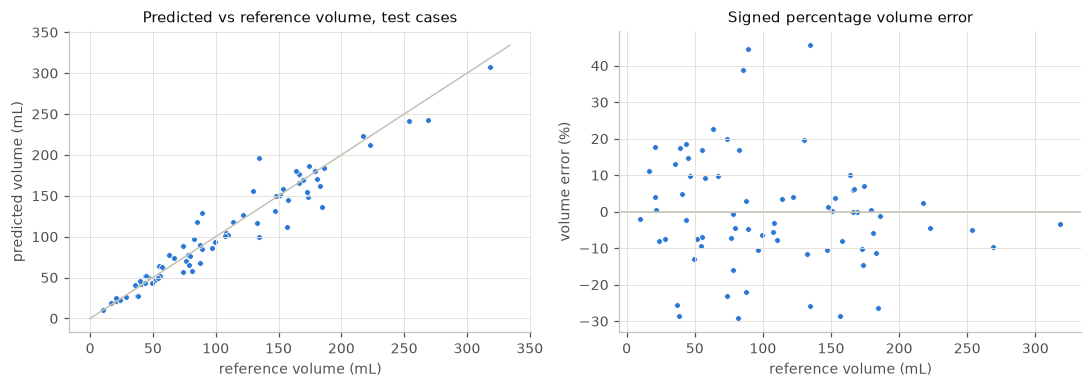

In [24]:
vol_cols = ["ref_ml", "pred_ml", "abs_vol_err_ml", "pct_vol_err"]
display(test_raw[vol_cols].round(1).sort_values("ref_ml"))
display(test_raw[vol_cols].agg(["mean", "std", "median"]).round(2))
print(f"Mean absolute percentage error: {test_raw.pct_vol_err.abs().mean():.1f} % "
      f"(median {test_raw.pct_vol_err.abs().median():.1f} %)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
lim = [0, max(test_raw.ref_ml.max(), test_raw.pred_ml.max()) * 1.05]
axes[0].plot(lim, lim, color=viz.AXIS, linewidth=1)
axes[0].scatter(test_raw.ref_ml, test_raw.pred_ml, s=14, color=viz.SAMPLER_COLOURS["uniform"], edgecolor="white", linewidth=0.5)
axes[0].set_xlabel("reference volume (mL)"), axes[0].set_ylabel("predicted volume (mL)")
axes[0].set_title("Predicted vs reference volume, test cases")
axes[1].axhline(0, color=viz.AXIS, linewidth=1)
axes[1].scatter(test_raw.ref_ml, test_raw.pct_vol_err, s=14, color=viz.SAMPLER_COLOURS["uniform"], edgecolor="white", linewidth=0.5)
axes[1].set_xlabel("reference volume (mL)"), axes[1].set_ylabel("volume error (%)")
axes[1].set_title("Signed percentage volume error")
plt.tight_layout(); save(fig, "fig_volumes"); plt.show()

### 6.4 Connected-component postprocessing: before and after on test

The rule and its threshold were fixed on validation in Section 5.2 and are applied unchanged. It is kept regardless of whether the test numbers below improve.

In [25]:
if MIN_COMPONENT_ML is not None:
    test_pp = ev.evaluate(test_probs, CACHE_DIR, meta, min_component_ml=MIN_COMPONENT_ML)
else:
    test_pp = test_raw.copy()
test_pp.to_csv(RESULTS_DIR / "test_metrics_postprocessed.csv")
cols = ["dice", "iou", "sensitivity", "hd95_mm", "fp_ml", "abs_vol_err_ml"]
before_after = pd.concat({"before": test_raw[cols].agg(["mean", "std", "median"]).T,
                          "after": test_pp[cols].agg(["mean", "std", "median"]).T}, axis=1)
display(before_after.round(3))
changed = (test_pp.dice != test_raw.dice).sum()
rule = f"remove components < {MIN_COMPONENT_ML} mL" if MIN_COMPONENT_ML is not None else "none (no threshold passed the validation criterion)"
print(f"Rule: {rule} | cases changed: {changed} of {len(test_ids)} | "
      f"empty predictions before/after: {int(test_raw.empty_pred.sum())}/{int(test_pp.empty_pred.sum())}")
FINAL_TEST = test_pp  # the pipeline as fixed on validation

before                  after               
                  mean     std median    mean     std median
dice             0.889   0.065  0.901   0.889   0.065  0.901
iou              0.805   0.099  0.819   0.806   0.098  0.820
sensitivity      0.888   0.086  0.907   0.887   0.086  0.907
hd95_mm          9.361  11.304  5.385   9.403  10.728  5.385
fp_ml            9.935  11.695  6.924   9.781  11.634  6.924
abs_vol_err_ml  11.296  12.052  6.829  11.282  12.050  6.628

Rule: remove components < 0.5 mL | cases changed: 61 of 73 | empty predictions before/after: 0/0


**Effect of the rule.** On validation, removing components smaller than 0.5 mL lowered median HD95 from 6.7 to 5.8 mm without lowering Dice, so it was fixed. On test it is close to neutral: mean Dice 0.888 → 0.889, mean false-positive volume 9.93 → 9.78 mL, median HD95 unchanged at 5.4 mm, and mean HD95 slightly *worse*, 9.36 → 9.41 mm. Case by case, HD95 improved in 21 test cases, got worse in 12 and was unchanged in 40. The worst change shows the rule's risk: in BRATS_253, HD95 rose from 10.4 to 32.0 mm because the removed islands were real, small, separate pieces of the reference; once deleted, those reference voxels became misses far from the remaining prediction. Small components are mostly false positives, but not always — fragmented or multifocal edema produces genuine small components. The rule is kept as fixed on validation; it is not retuned on the test result.

### 6.5 Effect of the near-duplicate scans on the test estimate

Final pipeline. Test cases are split by whether their scan also appears under another ID in train or validation (Section 2.1), then by *where* the twin is; a second check asks whether predictions copy the twin's training annotation.

In [26]:
twin = pd.Series([c in test_with_twin for c in FINAL_TEST.index], index=FINAL_TEST.index)
cols = ["dice", "iou", "sensitivity", "hd95_mm", "abs_vol_err_ml"]
dup_tab = pd.concat({"no twin in train/val": FINAL_TEST[~twin][cols].agg(["mean", "std", "median"]).T,
                     "twin in train/val": FINAL_TEST[twin][cols].agg(["mean", "std", "median"]).T}, axis=1)
display(dup_tab.round(3))
print(f"Cases: {int((~twin).sum())} without a twin, {int(twin.sum())} with | Mann-Whitney U on Dice: "
      f"p = {stats.mannwhitneyu(FINAL_TEST.dice[twin], FINAL_TEST.dice[~twin]).pvalue:.4f}")
twin_partner_dice = dup_pairs.set_index("case_a").label_dice.to_dict() | dup_pairs.set_index("case_b").label_dice.to_dict()
print(f"For the {int(twin.sum())} twin cases, agreement between their two reference annotations: "
      f"mean Dice {np.mean([twin_partner_dice[c] for c in FINAL_TEST.index[twin]]):.3f}")

# Does the gap come from having seen the scan? Split by where the twin is. A twin in validation or in the test
# split was never trained on, so if those cases score as high as cases with a twin in training, the gap is
# case mix (which cases have twins), not memorisation.
where = pd.Series({c: split_of[partner[c]] if c in partner else "no twin" for c in FINAL_TEST.index}, name="twin in")
by_where = FINAL_TEST.groupby(where).agg(cases=("dice", "size"), mean_dice=("dice", "mean"),
                                         median_dice=("dice", "median"), median_hd95=("hd95_mm", "median"))
display(by_where.loc[["no twin", "test", "validation", "train"]].round(3))
twin_free = FINAL_TEST.index[~twin]
print(f"The {len(twin_free)} 'twin-free' test cases contain {int(sum(c in partner for c in twin_free) / 2)} pairs of "
      f"each other (twins inside the test split) -> {len(twin_free) - int(sum(c in partner for c in twin_free) / 2)} "
      "distinct scans")


def pipeline_mask(prob, threshold, min_ml, cid):
    m = prob >= threshold
    return ev.remove_small_components(m, min_ml, meta[cid]["spacing"]) if min_ml else m


def full_label(cid):
    return data.uncrop(np.asarray(data.load_cached(CACHE_DIR, cid)[1]) > 0, meta[cid])


def memorisation_check(masks, label):
    """For test cases whose twin was trained on: is the prediction closer to the twin's (training) annotation
    than to the case's own annotation? A model that reproduced training labels would be."""
    rows = []
    for c, m in masks.items():
        pred, own, twin_lbl = data.uncrop(m, meta[c]), full_label(c), full_label(partner[c])
        rows.append({"case": c, "twin (train)": partner[c], "Dice vs own label": dice(pred, own),
                     "Dice vs twin's training label": dice(pred, twin_lbl), "annotations agree": dice(own, twin_lbl)})
    out = pd.DataFrame(rows).set_index("case")
    own_mean, twin_mean = out["Dice vs own label"].mean(), out["Dice vs twin's training label"].mean()
    gap = out["Dice vs twin's training label"] - out["Dice vs own label"]
    print(f"{label}, test cases with a twin in training (n = {len(out)}): Dice vs own label {own_mean:.3f}, vs the "
          f"twin's training label {twin_mean:.3f}; prediction closer to the training label in {int((gap > 0).sum())} "
          f"of {len(out)}; Wilcoxon p = {stats.wilcoxon(gap[gap != 0]).pvalue:.2f}")
    return out


train_twin_cases = FINAL_TEST.index[where == "train"]
mem_v1 = memorisation_check({c: pipeline_mask(test_probs[c], 0.5, MIN_COMPONENT_ML, c) for c in train_twin_cases}, "v1")

no twin in train/val                twin in train/val               
                               mean     std median              mean     std median
dice                          0.876   0.070  0.890             0.909   0.050  0.924
iou                           0.786   0.105  0.801             0.837   0.080  0.859
sensitivity                   0.879   0.087  0.900             0.900   0.085  0.919
hd95_mm                      11.311  11.608  6.702             6.509   8.638  4.123
abs_vol_err_ml               12.033  12.800  8.447            10.141  10.934  5.904

Cases: 44 without a twin, 29 with | Mann-Whitney U on Dice: p = 0.0245
For the 29 twin cases, agreement between their two reference annotations: mean Dice 0.915


,cases,mean_dice,median_dice,median_hd95
twin in,,,,
no twin,38,0.869,0.885,9.220
test,6,0.921,0.926,2.914
validation,6,0.906,0.921,5.012
train,23,0.910,0.924,4.123


The 44 'twin-free' test cases contain 3 pairs of each other (twins inside the test split) -> 41 distinct scans


v1, test cases with a twin in training (n = 23): Dice vs own label 0.910, vs the twin's training label 0.915; prediction closer to the training label in 11 of 23; Wilcoxon p = 0.92


**Interpretation.** The 29 test cases whose scan also appears in train or validation score higher than the other 44 (mean Dice 0.909 vs 0.876, Mann–Whitney p = 0.025). The breakdown by *where* the twin is shows that this is not because the model has seen the scan. Test cases whose twin is in validation (0.906, n = 6) or elsewhere in the test split (0.921, n = 6), scans the model never trained on, score as high as those whose twin is in training (0.910, n = 23); cases with no twin at all score 0.869 (n = 38). The memorisation check agrees: for the 23 cases whose twin was trained on, the prediction is no closer to the twin's training annotation than to the case's own (Dice 0.915 vs 0.910, closer in 11 of 23, Wilcoxon p = 0.92), and the median case of Section 7 (BRATS_281) misses a region that its training twin's label contains.

The gap is therefore **case mix**: the scans that appear twice are, on average, easier cases. The 73-case results of Sections 6.2–6.4 remain the estimate to use. The 44 "twin-free" cases are not a fairer estimate, only a harder subset, and they are 41 distinct scans, because three twin pairs lie inside the test split. What the duplication does cost is sample size: the 73 test cases hold 70 distinct scans, and the whole dataset 368 rather than 484.

## 7. Three-plane error analysis and limitations

### 7.1 Best, median and worst test cases by Dice

Final pipeline (final model, fixed postprocessing). Each plane is shown at the slice with the most misclassified voxels for that case, so errors are visible; the background is FLAIR. Reference = TP + FN, prediction = TP + FP.

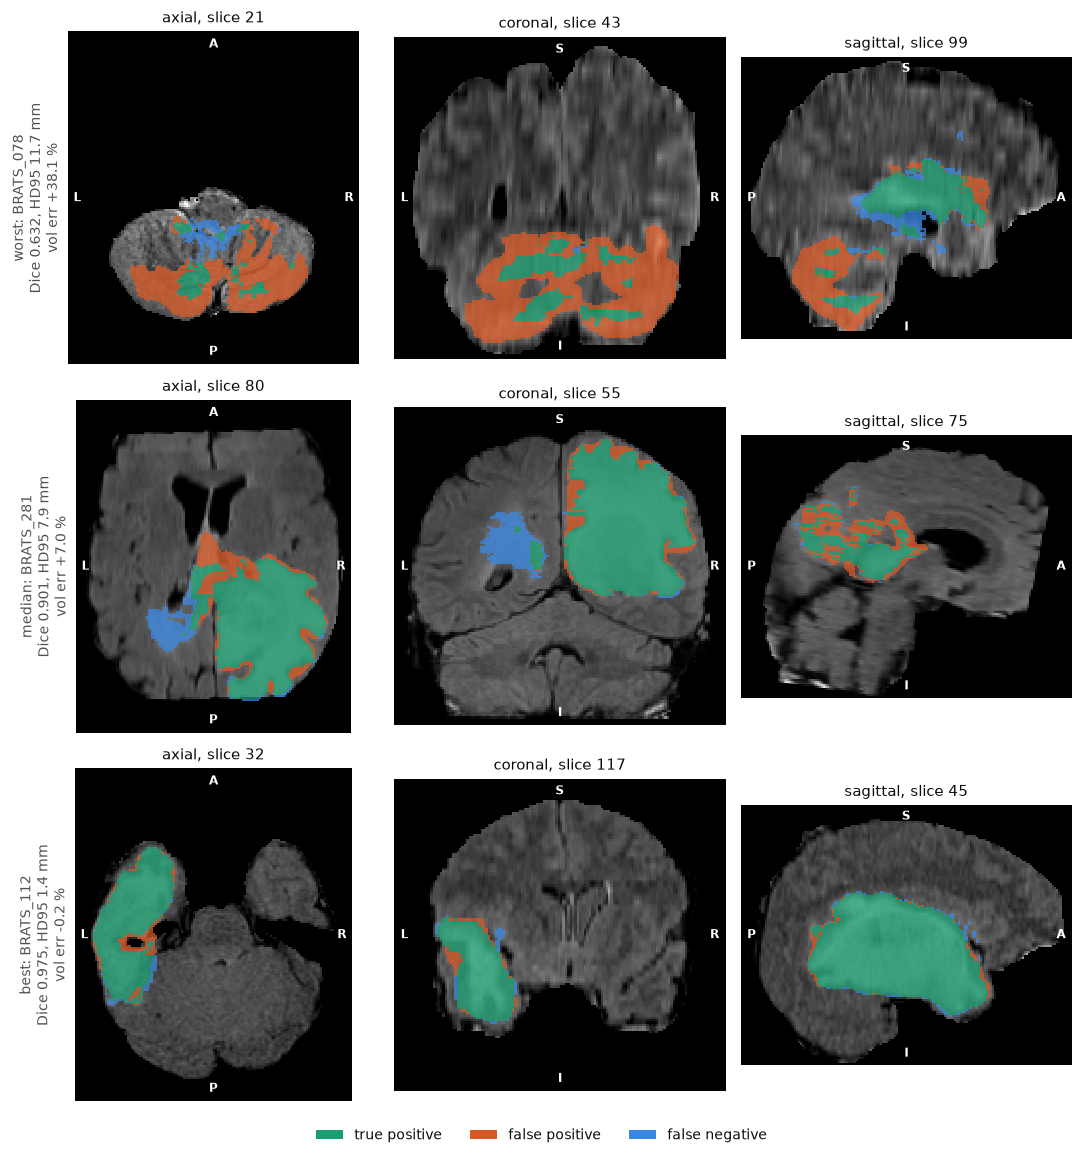

In [27]:
ranked = FINAL_TEST.sort_values("dice")
picks = {"worst": ranked.index[0], "median": ranked.index[len(ranked) // 2], "best": ranked.index[-1]}

def final_mask(cid):
    pred = test_probs[cid] >= 0.5
    if MIN_COMPONENT_ML is not None:
        pred = ev.remove_small_components(pred, MIN_COMPONENT_ML, meta[cid]["spacing"])
    return pred

fig, axes = plt.subplots(3, 3, figsize=(10, 10.5))
for row, (tag, cid_) in zip(axes, picks.items()):
    img_c, lbl_c = data.load_cached(CACHE_DIR, cid_)
    flair = np.asarray(img_c[0], dtype=np.float32)
    ref, pred = np.asarray(lbl_c) > 0, final_mask(cid_)
    overlay = viz.error_overlay(pred, ref)
    err = pred ^ ref
    sp_ = meta[cid_]["spacing"]
    r_ = FINAL_TEST.loc[cid_]
    for ax, plane in zip(row, ["axial", "coronal", "sagittal"]):
        ax_idx = viz.PLANES[plane]
        other = tuple(a for a in range(3) if a != ax_idx)
        idx = int(np.argmax(err.sum(other))) if err.any() else int(np.argmax(ref.sum(other)))
        viz.show_plane(ax, flair, plane, idx, sp_, overlay=overlay, vmin=-2, vmax=5, title=f"{plane}, slice {idx}")
    row[0].set_ylabel(f"{tag}: {cid_}\nDice {r_.dice:.3f}, HD95 {r_.hd95_mm:.1f} mm\nvol err {r_.pct_vol_err:+.1f} %",
                      fontsize=9)
fig.legend(handles=viz.legend_patches(viz.ERROR_COLOURS, {"TP": "true positive", "FP": "false positive",
                                                         "FN": "false negative"}), loc="lower center", ncol=3)
plt.tight_layout(rect=(0, 0.03, 1, 1)); save(fig, "fig_errors"); plt.show()

In [28]:
detail = []
for tag, cid_ in picks.items():
    pred = final_mask(cid_)
    _, lbl_c = data.load_cached(CACHE_DIR, cid_)
    ref = np.asarray(lbl_c)
    sizes = ev.component_sizes_ml(pred, meta[cid_]["spacing"])
    missed = {data.LABEL_NAMES[k]: f"{np.mean(~pred[ref == k]):.1%}" for k in (1, 2, 3) if (ref == k).any()}
    # How far false-negative voxels lie from the reference boundary (are misses at the edge or deep inside?)
    fn = (ref > 0) & ~pred
    depth = ndimage.distance_transform_edt(ref > 0, sampling=meta[cid_]["spacing"])[fn]
    detail.append({"case": f"{tag} {cid_}", **FINAL_TEST.loc[cid_, ["dice", "hd95_mm", "ref_ml", "pred_ml", "pct_vol_err",
                                                                  "fp_ml", "fn_ml"]].to_dict(),
                   "predicted components": len(sizes), "largest components (mL)": np.round(sizes[:3], 2).tolist(),
                   "missed fraction per sub-region": missed,
                   "FN within 2 mm of ref boundary": f"{np.mean(depth <= 2):.0%}" if fn.any() else "-"})
display(pd.DataFrame(detail).set_index("case").T)

case,worst BRATS_078,median BRATS_281,best BRATS_112
dice,0.632,0.901,0.975
hd95_mm,11.705,7.874,1.414
ref_ml,85.083,173.928,169.185
pred_ml,117.52,186.187,168.828
pct_vol_err,38.124,7.048,-0.211
fp_ml,53.504,23.984,4.086
fn_ml,21.067,11.725,4.443
predicted components,1,1,1
largest components (mL),[117.52],[186.19],[168.83]
missed fraction per sub-region,"{'edema': '24.2%', 'non-enhancing tumour': '19...","{'edema': '7.8%', 'non-enhancing tumour': '0.7...","{'edema': '4.5%', 'non-enhancing tumour': '0.2..."


**Relating the errors to their causes.**

- **Best — BRATS_112 (Dice 0.975, HD95 1.4 mm). Boundary quality.** All three planes show the errors as a one-voxel shell around a correctly placed region; 95 % of the missed voxels lie within 2 mm of the reference boundary and false-positive and missed volume balance (4.1 vs 4.4 mL, volume error −0.2 %). What remains is boundary placement at the scale of a single 1 mm voxel, i.e. the level at which two annotators also disagree.
- **Median — BRATS_281 (Dice 0.901, HD95 7.9 mm). A small separate structure.** The main tumour mass is captured, but the axial and coronal views show a separate region of edema across the midline, in the other hemisphere, entirely missed: one 8.1 mL component of the 11.7 mL false negative. It is much less conspicuous than the main lesion (median FLAIR z-score 0.97 vs 1.95 in the detected tumour; T2w 0.01 vs 1.48), and the network's probability there peaks at 0.499, just below the threshold. False positives are scattered along the margins of the main mass (sagittal view). This scan's twin in the training set carries an essentially identical label, yet the region is still missed, so the failure is one of weak signal, not of unseen anatomy.
- **Worst — BRATS_078 (Dice 0.632, HD95 11.7 mm, volume +38 %). Over-segmentation of tumour-like tissue.** 53.5 mL of false positive lies in the posterior fossa, about 30 mm below the reference tumour (median axial index 32 vs 62), in cerebellar tissue that is moderately bright on FLAIR (median z-score 0.95, against −0.14 for the rest of the brain and 1.84 inside correctly detected tumour). The false-positive region is connected to the true tumour (the prediction is a single 118 mL component), so the connected-component rule cannot remove it. A plausible explanation is limited patch context: a 64 mm window over the posterior fossa sees diffuse FLAIR brightness but not enough of the surrounding anatomy to separate edema from this region's normal signal. A further 21 mL of the reference is missed.

### 7.2 Dice versus HD95 and volume error

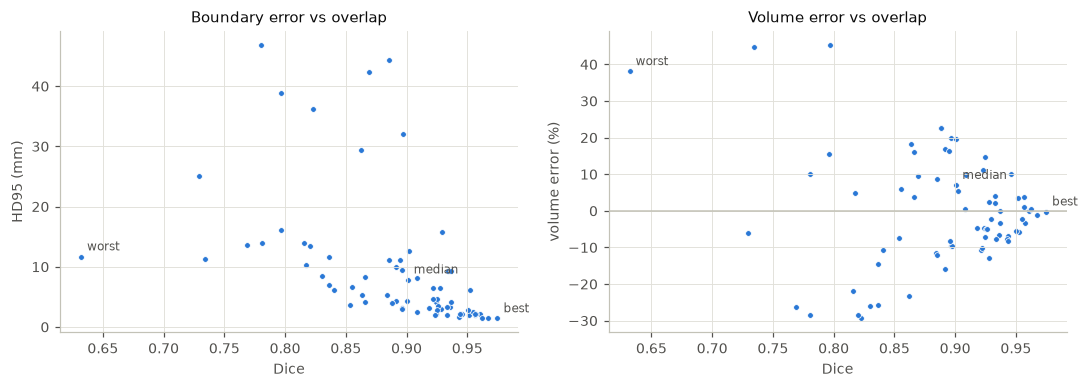

Spearman rank correlation, Dice vs HD95 over test cases: -0.76


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, col, lab in [(axes[0], "hd95_mm", "HD95 (mm)"), (axes[1], "pct_vol_err", "volume error (%)")]:
    ax.scatter(FINAL_TEST.dice, FINAL_TEST[col], s=14, color=viz.SAMPLER_COLOURS["uniform"], edgecolor="white", linewidth=0.5)
    for tag, cid_ in picks.items():
        ax.annotate(tag, (FINAL_TEST.loc[cid_, "dice"], FINAL_TEST.loc[cid_, col]), xytext=(4, 4),
                    textcoords="offset points", fontsize=8, color=viz.INK_2)
    ax.set_xlabel("Dice"), ax.set_ylabel(lab)
axes[0].set_title("Boundary error vs overlap"), axes[1].set_title("Volume error vs overlap")
axes[1].axhline(0, color=viz.AXIS, linewidth=1)
plt.tight_layout(); save(fig, "fig_dice_hd95"); plt.show()
rho = stats.spearmanr(FINAL_TEST.dice, FINAL_TEST.hd95_mm, nan_policy="omit")
print(f"Spearman rank correlation, Dice vs HD95 over test cases: {rho.statistic:.2f}")

**One metric cannot summarise every failure.** Over the test set Dice and HD95 are strongly but not perfectly related (Spearman −0.76), and the three highlighted cases already break the ranking: the worst case by Dice (BRATS_078, 0.632) has an unremarkable HD95 of 11.7 mm because its large false positive is *attached* to the tumour, so boundary distances stay around a centimetre, while its volume error (+38 %) is one of the largest. Other test cases show the reverse patterns:

- **BRATS_481**: Dice 0.89, close to the median, but HD95 44 mm, the second-highest; a small error far from the tumour dominates the 95th-percentile distance while barely affecting overlap.
- **BRATS_376**: Dice 0.73 but a volume error of only −6 %, because 2.4 mL of false positive and 3.0 mL of missed tumour cancel in the volume.
- **Small tumours** (reference < 40 mL, 11 cases): mean Dice 0.846 against 0.897 for larger ones; the same one-voxel boundary error is a larger fraction of a small object, so Dice penalises small structures.

Dice measures overlap relative to size, HD95 measures the worst part of the boundary in millimetres regardless of size, and volume error measures the quantity a clinician might track but is blind to *where* the errors are. Each misses a failure mode the others catch, so all three are reported.

### 7.3 Limitations

1. **Small training budget.** Each condition was trained once, for 5,000 iterations of 4 patches (about 70–80 minutes on one laptop GPU), with no hyperparameter search and validation loss still decreasing at the end (Section 10 shows how much a longer budget gains). The sampler comparison therefore has no estimate of seed-to-seed variability; differences of the size seen in Dice (0.005) could change sign with another seed, although the shifts in sensitivity, false-positive volume and HD95 were large and consistent across cases.
2. **No external-site validation.** Training, validation and test cases all come from one curated research collection (BraTS 2016/2017 via MSD), already co-registered, skull-stripped and resampled to 1 mm by the same pipeline. Performance on data from another hospital, scanner, protocol or preprocessing chain — or with a missing sequence (Section 8) — is unknown and likely lower.
3. **Case-level, not scan-level, split.** 116 scans appear twice under different IDs, and 29 of the 73 test cases have a twin in train or validation (Section 2.1). Cases with a twin score higher, but equally whether or not the twin was trained on, and the 64³ model's predictions are no closer to the twin's training annotation (Section 6.5): the gap is case mix, not measurable memorisation. For the longer-trained v2 model the predictions lean slightly towards the training annotations (closer in 16 of 23 cases, p = 0.10; Section 10), a weak hint that memorisation grows with training time. The duplication also leaves fewer independent scans than case IDs (368 of 484; 70 distinct scans among the 73 test cases).
4. **The reference is itself uncertain.** Labels are research annotations, not pathology-confirmed tumour extent; two annotations of the same scan in this dataset agree at a mean Dice of only 0.92. Test metrics measure agreement with one annotation and cannot exceed this level of label noise in a meaningful way.
5. **Fixed, uncalibrated decisions.** The 0.5 threshold, 64 mm patch size and 50 % overlap were chosen a priori, not tuned; probabilities are not calibrated (the sampler visibly shifts them), and only the binary whole-tumour target was modelled, not the clinically relevant sub-regions. The left–right direction is taken from the header and could not be verified from image content.

## 8. Bonus A — Missing-modality stress test

Without retraining, each MRI channel is replaced by zeros at test time in turn, and the final model (with the fixed postprocessing) is re-evaluated on the test split.

,median Dice,"median HD95 (mm, empty = worst)",median |vol err| (mL),median vol err (%),mean Dice,empty
input,,,,,,
all four channels,0.901,5.385,6.628,-2.174,0.889,0
FLAIR zeroed,0.054,45.365,78.274,-97.223,0.205,29
T1w zeroed,0.858,31.890,19.023,21.893,0.824,0
T1gd zeroed,0.891,6.403,10.845,-7.509,0.864,0
T2w zeroed,0.806,12.083,20.304,-21.630,0.726,1


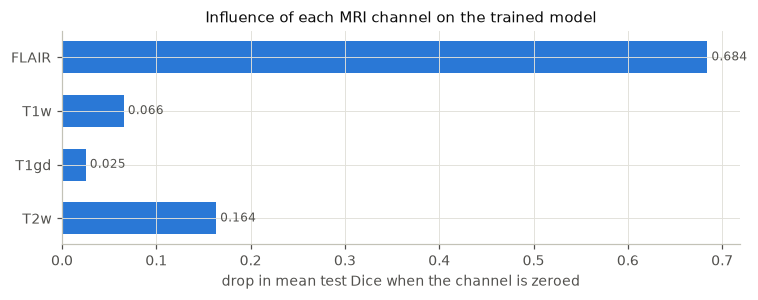

In [30]:
# Median HD95 counts an empty prediction as the worst case (infinitely far) instead of dropping it, so a
# condition that leaves many cases empty is not summarised by only the cases it still found.
mm_rows = [{"input": "all four channels", "dice": FINAL_TEST.dice.median(),
            "hd95_mm": ev.median_hd95_empty_worst(FINAL_TEST),
            **FINAL_TEST[["abs_vol_err_ml", "pct_vol_err"]].median().to_dict(),
            "mean Dice": FINAL_TEST.dice.mean(), "empty": int(FINAL_TEST.empty_pred.sum())}]
mm_results = {}
for c, name in enumerate(CHANNELS):
    probs_c, _ = ev.predict_probs(final_model, CACHE_DIR, test_ids, cfg_u.patch, 0.5, DEVICE,
                                  out_dir=PRED_DIR / f"test_{FINAL}_zero_{name}", zero_channel=c)
    r = ev.evaluate(probs_c, CACHE_DIR, meta, min_component_ml=MIN_COMPONENT_ML)
    mm_results[name] = r
    mm_rows.append({"input": f"{name} zeroed", "dice": r.dice.median(), "hd95_mm": ev.median_hd95_empty_worst(r),
                    **r[["abs_vol_err_ml", "pct_vol_err"]].median().to_dict(),
                    "mean Dice": r.dice.mean(), "empty": int(r.empty_pred.sum())})
mm = pd.DataFrame(mm_rows).set_index("input").rename(columns={"dice": "median Dice", "hd95_mm": "median HD95 (mm, empty = worst)",
                                                               "abs_vol_err_ml": "median |vol err| (mL)",
                                                               "pct_vol_err": "median vol err (%)"})
display(mm.round(3))

fig, ax = plt.subplots(figsize=(7, 2.8))
drops = [FINAL_TEST.dice.mean() - mm_results[n].dice.mean() for n in CHANNELS]
ax.barh(CHANNELS, drops, color=viz.SAMPLER_COLOURS["uniform"], height=0.6)
for y, d in enumerate(drops):
    ax.text(d, y, f" {d:.3f}", va="center", fontsize=8, color=viz.INK_2)
ax.invert_yaxis(), ax.set_xlabel("drop in mean test Dice when the channel is zeroed")
ax.set_title("Influence of each MRI channel on the trained model")
plt.tight_layout(); save(fig, "fig_bonus_modality"); plt.show()

**Interpretation.** FLAIR is by far the most influential channel: zeroing it drops mean test Dice from 0.889 to 0.205 and leaves 29 of 73 predictions empty (median volume error −97 %). T2w is second (mean Dice 0.726, systematic under-segmentation, median −22 %), T1w third (0.824, but over-segmentation of +22 % and median HD95 rising from 5.4 to 31.9 mm), and contrast-enhanced T1 matters least (0.864). This ordering matches what defines the target: whole tumour is dominated by peritumoural edema, which is identified by FLAIR and T2 hyperintensity, whereas T1gd mainly outlines the enhancing core, a small part of the whole-tumour volume.

Zeroing is an imperfect simulation of a missing acquisition. After brain z-scoring, 0 is not "no information" but the channel's *mean brain intensity*, so the network receives a perfectly flat, average-tissue image — an input it never saw in training and has no way to recognise as missing. Its response is therefore out-of-distribution behaviour (here sometimes over- and sometimes under-segmentation), not the graceful degradation a real missing sequence would require. A genuinely missing scan would also be known in advance, which this model cannot be told.

To handle missing modalities by design, training could use *modality dropout*: randomly remove one or more channels per patch and add a binary availability indicator per channel, so the network learns to use any subset and knows which one it has. Alternatives are per-modality encoders fused with order-invariant pooling (as in HeMIS), or separate models for the common sequence subsets.

## 9. Bonus B — Sliding-window seam test

The final model is run on the test split with 0 %, 25 % and 50 % window overlap (strides 64, 48 and 32), all with Gaussian blending and the fixed postprocessing. Runtime is the measured inference time per case on the same device.

In [31]:
seam = {}
for ov in [0.0, 0.25, 0.5]:
    out_dir = PRED_DIR / f"test_{FINAL}" if ov == 0.5 else PRED_DIR / f"test_{FINAL}_overlap{int(ov * 100)}"
    probs_o, secs_o = ev.predict_probs(final_model, CACHE_DIR, test_ids, cfg_u.patch, ov, DEVICE, out_dir=out_dir)
    r = ev.evaluate(probs_o, CACHE_DIR, meta, min_component_ml=MIN_COMPONENT_ML)
    seam[ov] = {"probs": probs_o, "metrics": r, "seconds": np.nanmean(list(secs_o.values()))}
seam_table = pd.DataFrame({f"{int(ov * 100)} %": {
    "stride (voxels)": int(round(64 * (1 - ov))),
    "windows per case (median)": np.median([n_windows(tuple(meta[c]["crop_shape"]), 64, ov) for c in test_ids]),
    "seconds per case": s["seconds"], "mean Dice": s["metrics"].dice.mean(), "median Dice": s["metrics"].dice.median(),
    "median HD95 (mm)": s["metrics"].hd95_mm.median(), "mean HD95 (mm)": s["metrics"].hd95_mm.mean(),
    "median |vol err| (mL)": s["metrics"].abs_vol_err_ml.median()} for ov, s in seam.items()})
display(seam_table.round(3))

,0 %,25 %,50 %
stride (voxels),64.000,48.000,32.000
windows per case (median),27.000,36.000,80.000
seconds per case,0.347,0.447,0.989
mean Dice,0.872,0.884,0.889
median Dice,0.897,0.900,0.901
median HD95 (mm),5.099,5.385,5.385
mean HD95 (mm),10.070,9.113,9.403
median |vol err| (mL),9.419,8.148,6.628


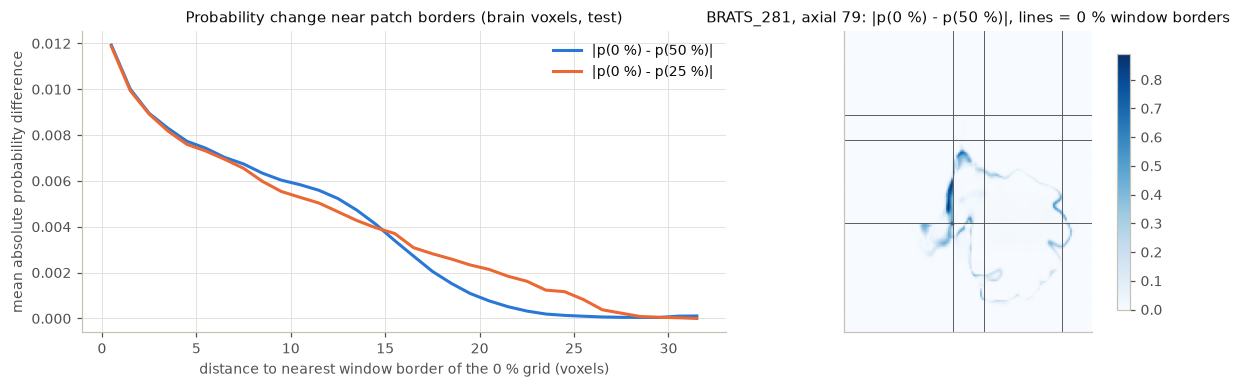

In [32]:
def distance_to_seam(shape, patch=64, stride=64):
    # Voxel distance to the nearest internal window edge of the given window grid (inf where there is none).
    per_axis = []
    for n in shape:
        edges = sorted({e for s in window_starts(n, patch, stride) for e in (s, s + patch) if 0 < e < n})
        x = np.arange(n) + 0.5
        d = np.min(np.abs(x[:, None] - np.array(edges)[None, :]), 1) if edges else np.full(n, np.inf)
        per_axis.append(d)
    return np.minimum.reduce(np.meshgrid(*per_axis, indexing="ij"))

bins = np.arange(0, 33)
sums, counts = np.zeros((2, len(bins) - 1)), np.zeros(len(bins) - 1)
for cid_ in test_ids:
    p0, p25, p50 = (seam[ov]["probs"][cid_] for ov in (0.0, 0.25, 0.5))
    img_c, _ = data.load_cached(CACHE_DIR, cid_)
    brain_c = np.asarray(img_c[0]) != 0
    d = distance_to_seam(p0.shape)[brain_c]
    idx = np.digitize(d, bins) - 1
    ok = (idx >= 0) & (idx < len(bins) - 1)
    for row_, other in enumerate([p50, p25]):
        sums[row_] += np.bincount(idx[ok], weights=np.abs(p0 - other)[brain_c][ok], minlength=len(bins) - 1)
    counts += np.bincount(idx[ok], minlength=len(bins) - 1)
centres = bins[:-1] + 0.5
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
axes[0].plot(centres, sums[0] / counts, color=viz.SAMPLER_COLOURS["uniform"], label="|p(0 %) - p(50 %)|")
axes[0].plot(centres, sums[1] / counts, color=viz.SAMPLER_COLOURS["tumour"], label="|p(0 %) - p(25 %)|")
axes[0].set_xlabel("distance to nearest window border of the 0 % grid (voxels)")
axes[0].set_ylabel("mean absolute probability difference")
axes[0].set_title("Probability change near patch borders (brain voxels, test)")
axes[0].legend()
# One slice: the 0 % overlap probability map next to the difference map
cid_ = picks["median"]
k_ = int(np.argmax((test_probs[cid_] >= 0.5).sum((0, 1))))
diff_sl = np.abs(seam[0.0]["probs"][cid_] - seam[0.5]["probs"][cid_])[:, :, k_].T
im_ = axes[1].imshow(diff_sl, origin="lower", cmap="Blues", vmin=0, vmax=max(diff_sl.max(), 1e-3))
for e in sorted({e for s in window_starts(diff_sl.shape[1], 64, 64) for e in (s, s + 64) if 0 < e < diff_sl.shape[1]}):
    axes[1].axvline(e - 0.5, color=viz.INK_2, linewidth=0.6)
for e in sorted({e for s in window_starts(diff_sl.shape[0], 64, 64) for e in (s, s + 64) if 0 < e < diff_sl.shape[0]}):
    axes[1].axhline(e - 0.5, color=viz.INK_2, linewidth=0.6)
axes[1].set_title(f"{cid_}, axial {k_}: |p(0 %) - p(50 %)|, lines = 0 % window borders")
axes[1].set_xticks([]), axes[1].set_yticks([]), axes[1].grid(False)
fig.colorbar(im_, ax=axes[1], shrink=0.85)
plt.tight_layout(); save(fig, "fig_bonus_seam"); plt.show()

**Interpretation.** Runtime scales with the number of windows: 27 windows and 0.35 s per case at 0 % overlap, 36 and 0.45 s at 25 %, 80 and 0.99 s at 50 % (2.8 times slower). Accuracy improves less: mean Dice 0.872 → 0.884 → 0.889, while median Dice barely moves (0.897 → 0.901) and median HD95 does not improve (5.1, 5.4, 5.4 mm), so the gain comes from a minority of cases with poor predictions near window borders. The plot shows why: the 0 % vs 50 % probability difference is largest exactly at the 0 % window borders (about 0.012) and fades to almost nothing 25–30 voxels inside. Border voxels are predicted with one-sided context and zero padding; overlap lets each also be predicted from a window where it is central, and the Gaussian weighting favours that prediction. Overlap therefore helps most when structures are large relative to the window and cross its borders, as here, and least when the window is large or the object lies inside one window. (At "0 %" the last window per axis still overlaps its neighbour.)

Choosing the overlap by repeatedly comparing these test results would turn the test set into a tuning set: the setting that happens to fit these 73 cases best would be picked and its score biased upwards. The 50 % overlap was fixed before the test split was evaluated; this test only describes the effect.

## 10. Improved model (v2): larger patches and longer training

*Beyond the brief.* Sections 4–9 answer the brief with the 64³ models. Their learning curves showed a budget-limited model (validation loss still falling at the end, Section 4.5), so a second version was trained afterwards. To keep the comparison honest:
- every v2 choice uses validation data only, and the selection rule of Section 10.1 was written into `a2/final_v2.py` before any v2 validation result was computed;
- the test split is evaluated once, in Section 10.2, with the frozen v2 pipeline;
- the test split *had* already been evaluated once (Section 6) before this work began, so the v2 test result is a second look at it. No v2 decision used it, but the order of events should be clear.

**What changed** (`a2/train_v2.py`, `a2/sampling_v2.py`). Everything else is as in Section 4: architecture, loss, AdamW, learning rate 10⁻³ with cosine decay, and seed 2440, so all four runs start from the same weights.
- **96³ patches × 2 for 40,000 iterations:** about 13× the training voxels of the 64³ runs.
- **Stronger training-only augmentation:** rotation up to ±15° about each axis and isotropic scaling ×0.9–1.1 (p = 0.25; image linear, mask nearest-neighbour interpolation); per-channel gamma 0.7–1.5 keeping the brain mean and SD (p = 0.3); Gaussian noise (p = 0.15); plus the flip and intensity scale/shift of Section 3.4.
- **Faster, exact convolutions** (`a2/fastconv.py`). On Apple's MPS backend the weight gradient of `nn.Conv3d` is very slow. Each 3×3×3 convolution is therefore computed as one 2D convolution over three depth-shifted copies of the input, and each 2×2×2 transposed convolution as a per-voxel matrix product. The parameters are unchanged, so the weights load into the plain U-Net. One training iteration became about 3× faster (96³ × 2: 1.16 → 0.39 s), which made 2 × 4.5 h of training affordable.
- **Both samplers were trained again.** At 96³ almost every patch contains tumour under either sampler (table below), which is why Section 4 used 64³ for the controlled comparison. Here the second model is a candidate for averaging.

The next cell checks that the fast layers compute the same function and lists the four runs.

Fast layers: same parameter names and shapes: True; max |logit difference| on a random 48^3 input: 2.4e-05
[uniform96] reusing finished run from models
[tumour96] reusing finished run from models
All four runs (64^3 and 96^3, both samplers) start from the same weights: 3ab1bbaff442


,patch x batch,iterations,training voxels (1e9),patches with tumour,tumour fraction of patch voxels,runtime (h),validation loss (73 cases),"validation Dice (73 cases, thr 0.5)"
run,,,,,,,,
"uniform, 64^3 (Section 4)",64^3 x 4,5000,5.243,0.790,0.072,1.162,0.169,0.876
"tumour-aware, 64^3 (Section 4)",64^3 x 4,5000,5.243,0.901,0.161,1.309,0.205,0.871
uniform96,96^3 x 2,40000,70.779,0.993,0.070,4.513,0.118,0.908
tumour96,96^3 x 2,40000,70.779,0.996,0.089,4.435,0.117,0.909


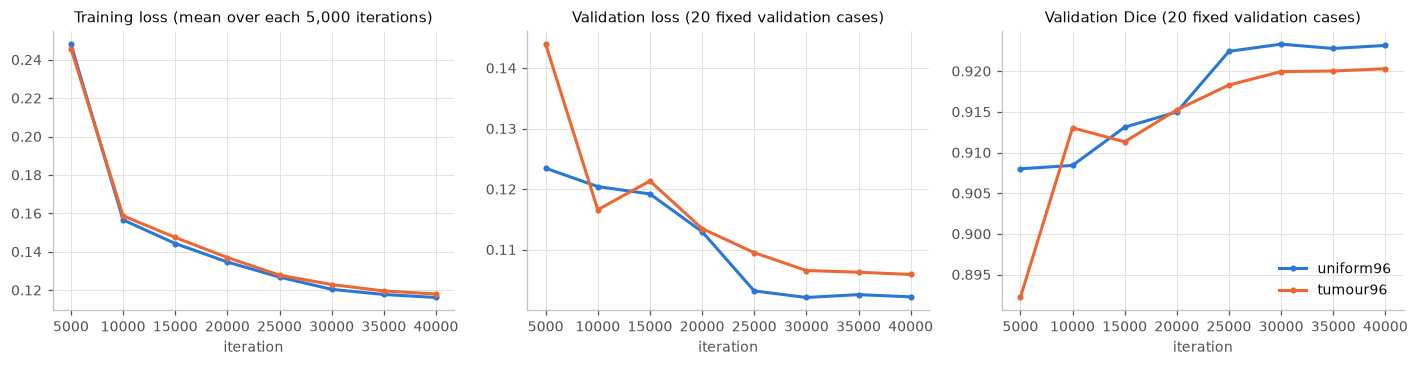

In [33]:
import copy

from a2 import final_v2 as v2
from a2.fastconv import make_fast
from a2.train_v2 import EXPERIMENTS_V2, train_v2

# 1. The faster layers compute the same function: same parameter names and shapes, same outputs
ref_net = UNet3D(features=cfg_u.features).eval()
fast_net = make_fast(copy.deepcopy(ref_net)).eval()
x_chk = torch.randn(1, 4, 48, 48, 48)
with torch.no_grad():
    max_diff = (ref_net(x_chk) - fast_net(x_chk)).abs().max().item()
same_params = [(k, tuple(v.shape)) for k, v in ref_net.state_dict().items()] == \
              [(k, tuple(v.shape)) for k, v in fast_net.state_dict().items()]
print(f"Fast layers: same parameter names and shapes: {same_params}; "
      f"max |logit difference| on a random 48^3 input: {max_diff:.1e}")

# 2. The two v2 runs (reused from models/ when the configuration matches; otherwise about 4.5 h each)
runs_v2 = {n: train_v2(EXPERIMENTS_V2[n], CACHE_DIR, train_ids, val_ids, MODEL_DIR, device=DEVICE)
           for n in ("uniform96", "tumour96")}
hist_v2 = {n: h for n, (_, h) in runs_v2.items()}
assert hist_v2["uniform96"]["init_hash"] == hist_v2["tumour96"]["init_hash"] == hist_u["init_hash"]
print("All four runs (64^3 and 96^3, both samplers) start from the same weights:", hist_u["init_hash"])

rows = []
for label, cfg, h, final_dice, final_loss in [
        ("uniform, 64^3 (Section 4)", cfg_u, hist_u, hist_u["val_dice"][-1], hist_u["val_loss"][-1]),
        ("tumour-aware, 64^3 (Section 4)", cfg_t, hist_t, hist_t["val_dice"][-1], hist_t["val_loss"][-1]),
        ("uniform96", EXPERIMENTS_V2["uniform96"], hist_v2["uniform96"], hist_v2["uniform96"]["full_val_dice"],
         hist_v2["uniform96"]["full_val_loss"]),
        ("tumour96", EXPERIMENTS_V2["tumour96"], hist_v2["tumour96"], hist_v2["tumour96"]["full_val_dice"],
         hist_v2["tumour96"]["full_val_loss"])]:
    ds = PatchDataset(CACHE_DIR, train_ids, cfg.patch, cfg.iterations * cfg.batch_size, cfg.sampler, cfg.fg_prob,
                      seed=cfg.seed)
    has, frac = tumour_fraction(ds, n=5000)
    rows.append({"run": label, "patch x batch": f"{cfg.patch}^3 x {cfg.batch_size}", "iterations": cfg.iterations,
                 "training voxels (1e9)": cfg.patch ** 3 * cfg.batch_size * cfg.iterations / 1e9,
                 "patches with tumour": has, "tumour fraction of patch voxels": frac,
                 "runtime (h)": h["runtime_min"] / 60, "validation loss (73 cases)": final_loss,
                 "validation Dice (73 cases, thr 0.5)": final_dice})
display(pd.DataFrame(rows).set_index("run").round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for n, colour in [("uniform96", "uniform"), ("tumour96", "tumour")]:
    for ax, key in zip(axes, ["train_loss", "val_loss", "val_dice"]):
        ax.plot(hist_v2[n]["iteration"], hist_v2[n][key], color=viz.SAMPLER_COLOURS[colour], label=n, marker="o",
                markersize=3)
axes[0].set_title("Training loss (mean over each 5,000 iterations)")
axes[1].set_title("Validation loss (20 fixed validation cases)")
axes[2].set_title("Validation Dice (20 fixed validation cases)")
for ax in axes:
    ax.set_xlabel("iteration")
axes[2].legend(loc="lower right")
plt.tight_layout(); save(fig, "fig_curves_v2"); plt.show()

### 10.1 Selection on validation

Each candidate pipeline averages some of four probability maps: uniform96 (U), tumour96 (T), and each model applied to the left–right mirrored volume with the map mirrored back (Uf, Tf; *test-time flip augmentation*). All use 96³ windows, 50 % overlap and Gaussian blending (Section 6.1). Thresholds 0.5, 0.4 and 0.6 are tried.

**Rule, fixed in `a2/final_v2.py` before any v2 result was computed.** Find the highest mean validation Dice over all candidates and thresholds (no postprocessing). Every option within 0.002 of it counts as equivalent, and the simplest equivalent wins: one model, then one model + flip, then both models, then both models + flip; within that, threshold 0.5 before 0.4 or 0.6. Simpler is preferred because it is cheaper, easier to explain and less tuned to these 73 cases. The connected-component threshold is then chosen with the criterion of Section 5.2.

In [34]:
models_v2 = {"U": runs_v2["uniform96"][0].eval(), "T": runs_v2["tumour96"][0].eval()}
dirs_val_v2 = v2.component_dirs(models_v2, CACHE_DIR, val_ids, DEVICE, PRED_DIR / "val_v2")
sweep_val_v2 = v2.sweep(dirs_val_v2, CACHE_DIR, val_ids, meta)
V2_CANDIDATE, V2_THRESHOLD, ranked_v2 = v2.select(sweep_val_v2)
display(ranked_v2.round(4))
print(f"Best mean validation Dice {ranked_v2.mean_dice.max():.4f}; options within {v2.MARGIN} of it count as "
      f"equivalent. Selected (simplest equivalent): {V2_CANDIDATE}, threshold {V2_THRESHOLD}")

# The two v2 samplers on validation (threshold 0.5, no postprocessing), as in Section 5
cols = ["dice", "sensitivity", "fp_ml", "fn_ml", "hd95_mm"]
s05 = sweep_val_v2[sweep_val_v2.threshold == 0.5]
u96, t96 = (s05[s05.candidate == n].set_index("case_id")[cols] for n in ("uniform96", "tumour96"))
comp_v2 = pd.DataFrame({"uniform96 mean": u96.mean(), "tumour96 mean": t96.mean(),
                        "mean paired diff": (t96 - u96).mean(), "cases tumour96 higher": (t96 > u96).sum(),
                        "Wilcoxon p": [wilcoxon_p(t96[c], u96[c]) for c in cols]})
display(comp_v2.round(4))

,candidate,threshold,mean_dice,median_dice,sensitivity,fp_ml,median_hd95,mean_hd95,empty,level,equivalent
0,tumour96 + flip,0.5,0.911,0.921,0.919,7.939,3.317,8.319,0,2,True
1,tumour96 + flip,0.6,0.911,0.921,0.910,6.918,3.317,8.158,0,2,True
2,uniform96 + tumour96,0.5,0.913,0.926,0.918,7.690,3.162,6.238,0,3,True
3,uniform96 + tumour96,0.6,0.912,0.923,0.906,6.505,3.317,6.441,0,3,True
4,uniform96 + tumour96,0.4,0.911,0.920,0.928,9.189,3.317,7.345,0,3,True
5,uniform96 + tumour96 + flip,0.5,0.913,0.925,0.917,7.644,3.146,6.283,0,4,True
6,uniform96 + tumour96 + flip,0.4,0.912,0.919,0.928,9.041,3.162,6.313,0,4,True
7,uniform96 + tumour96 + flip,0.6,0.912,0.925,0.906,6.486,3.278,6.449,0,4,True
8,tumour96,0.5,0.909,0.920,0.918,8.047,3.464,8.244,0,1,False
9,uniform96,0.5,0.908,0.918,0.913,8.189,3.317,7.219,0,1,False


Best mean validation Dice 0.9127; options within 0.002 of it count as equivalent. Selected (simplest equivalent): tumour96 + flip, threshold 0.5


,uniform96 mean,tumour96 mean,mean paired diff,cases tumour96 higher,Wilcoxon p
dice,0.908,0.909,9.000e-04,41,0.290
sensitivity,0.913,0.918,4.900e-03,37,0.268
fp_ml,8.189,8.047,-1.422e-01,34,0.762
fn_ml,7.944,7.535,-4.087e-01,36,0.347
hd95_mm,7.219,8.244,1.025e+00,25,0.409


In [35]:
v2_tags = v2.CANDIDATES[V2_CANDIDATE][1]
val_probs_v2 = v2.averaged_maps(dirs_val_v2, v2_tags, val_ids)
V2_MIN_COMPONENT_ML, rule_table_v2 = v2.choose_component_rule(val_probs_v2, CACHE_DIR, meta, V2_THRESHOLD)
display(rule_table_v2.round(4))
print(f"Component rule for v2 (v1 criterion): remove components < {V2_MIN_COMPONENT_ML} mL"
      if V2_MIN_COMPONENT_ML else "Component rule for v2: none")

# Final pipelines on validation: v1 (Section 5) against v2
val_v1_final = ev.evaluate(val_probs, CACHE_DIR, meta, min_component_ml=MIN_COMPONENT_ML)
val_v2_final = ev.evaluate(val_probs_v2, CACHE_DIR, meta, threshold=V2_THRESHOLD, min_component_ml=V2_MIN_COMPONENT_ML)
cols = ["dice", "sensitivity", "fp_ml", "hd95_mm", "abs_vol_err_ml"]
d = val_v2_final[cols] - val_v1_final[cols]
display(pd.DataFrame({"v1 mean": val_v1_final[cols].mean(), "v1 median": val_v1_final[cols].median(),
                      "v2 mean": val_v2_final[cols].mean(), "v2 median": val_v2_final[cols].median(),
                      "mean paired diff": d.mean(), "cases v2 higher": (d > 0).sum(),
                      "Wilcoxon p": [wilcoxon_p(val_v2_final[c], val_v1_final[c]) for c in cols]}).round(4))
rule_text = f"components < {V2_MIN_COMPONENT_ML} mL removed" if V2_MIN_COMPONENT_ML else "no postprocessing"
print(f"Frozen v2 pipeline: {V2_CANDIDATE}, threshold {V2_THRESHOLD}, {rule_text}. Nothing below changes it.")

,dice mean,dice median,hd95_mm mean,hd95_mm median
T_ml,,,,
none,0.911,0.921,8.319,3.317
0.05,0.911,0.921,8.312,3.317
0.1,0.911,0.921,8.291,3.317
0.25,0.911,0.921,8.238,3.317
0.5,0.911,0.921,8.382,3.317
1.0,0.912,0.921,7.692,3.317
2.0,0.912,0.921,6.747,3.317


Component rule for v2: none


,v1 mean,v1 median,v2 mean,v2 median,mean paired diff,cases v2 higher,Wilcoxon p
dice,0.877,0.901,0.911,0.921,0.034,65,0.000e+00
sensitivity,0.885,0.910,0.919,0.941,0.034,48,3.000e-04
fp_ml,10.579,7.463,7.939,6.022,-2.640,22,3.000e-04
hd95_mm,13.811,5.827,8.319,3.317,-5.492,14,0.000e+00
abs_vol_err_ml,10.260,8.046,6.959,4.932,-3.301,25,2.000e-04


Frozen v2 pipeline: tumour96 + flip, threshold 0.5, no postprocessing. Nothing below changes it.


### 10.2 Test evaluation of the frozen v2 pipeline

The pipeline printed above is final. The next cell applies it to the 73 test cases, once, and compares it case by case with the v1 result of Section 6 (`FINAL_TEST`: uniform 64³ model, threshold 0.5, components < 0.5 mL removed). It then repeats the near-duplicate checks of Section 6.5 for v2.

In [36]:
dirs_test_v2 = v2.component_dirs(models_v2, CACHE_DIR, test_ids, DEVICE, PRED_DIR / "test_v2", tags=v2_tags)
test_probs_v2 = v2.averaged_maps(dirs_test_v2, v2_tags, test_ids)
test_v2_raw = ev.evaluate(test_probs_v2, CACHE_DIR, meta, threshold=V2_THRESHOLD)
TEST_V2 = test_v2_raw if V2_MIN_COMPONENT_ML is None else     ev.evaluate(test_probs_v2, CACHE_DIR, meta, threshold=V2_THRESHOLD, min_component_ml=V2_MIN_COMPONENT_ML)
TEST_V2.to_csv(RESULTS_DIR / "test_metrics_v2.csv")
v2_secs = sum(np.nanmean(list(json.loads((dirs_test_v2[t] / "timing.json").read_text()).values())) for t in v2_tags)

cols = ["dice", "iou", "sensitivity", "hd95_mm", "fp_ml", "abs_vol_err_ml", "pct_vol_err"]
def msd(df):
    return df[cols].agg(["mean", "std", "median"]).T
d = TEST_V2[cols] - FINAL_TEST[cols]
tables = {"v1 (Section 6)": msd(FINAL_TEST)}
if V2_MIN_COMPONENT_ML is not None:
    tables["v2 before postprocessing"] = msd(test_v2_raw)
tables["v2"] = msd(TEST_V2)
v1_v2 = pd.concat(tables, axis=1)
v1_v2[("v2 - v1", "mean paired diff")] = d.mean()
v1_v2[("v2 - v1", "cases v2 higher")] = (d > 0).sum()
v1_v2[("v2 - v1", "Wilcoxon p")] = [wilcoxon_p(TEST_V2[c], FINAL_TEST[c]) for c in cols]
display(v1_v2.round(3))
print(f"Empty predictions: v1 {int(FINAL_TEST.empty_pred.sum())}, v2 {int(TEST_V2.empty_pred.sum())} of {len(TEST_V2)} | "
      f"inference: v1 {np.nanmean(list(test_secs.values())):.2f} s, v2 {v2_secs:.2f} s per case on {DEVICE}")

# Same case-mix check as Section 6.5
by_where_v2 = pd.DataFrame({"cases": FINAL_TEST.groupby(where).size(), "v1 mean Dice": FINAL_TEST.dice.groupby(where).mean(),
                            "v2 mean Dice": TEST_V2.dice.groupby(where).mean()})
display(by_where_v2.loc[["no twin", "test", "validation", "train"]].round(3))
mem_v2 = memorisation_check({c: pipeline_mask(test_probs_v2[c], V2_THRESHOLD, V2_MIN_COMPONENT_ML, c)
                             for c in train_twin_cases}, "v2")
worst ={"v1 worst (Section 7)": picks["worst"], "v1 median": picks["median"], "v1 best": picks["best"]}
display(pd.DataFrame({k: {"case": c, "v1 Dice": FINAL_TEST.dice[c], "v2 Dice": TEST_V2.dice[c],
                          "v1 HD95": FINAL_TEST.hd95_mm[c], "v2 HD95": TEST_V2.hd95_mm[c]} for k, c in worst.items()}).T)

v1 (Section 6)                    v2                         v2 - v1                           
                         mean     std median   mean     std median mean paired diff cases v2 higher Wilcoxon p
dice                    0.889   0.065  0.901  0.911   0.055  0.927            0.021              62      0.000
iou                     0.806   0.098  0.820  0.840   0.086  0.865            0.034              62      0.000
sensitivity             0.887   0.086  0.907  0.912   0.061  0.928            0.024              44      0.000
hd95_mm                 9.403  10.728  5.385  7.986  11.244  4.123           -1.417              18      0.002
fp_ml                   9.781  11.634  6.924  7.672   8.279  5.431           -2.109              23      0.000
abs_vol_err_ml         11.282  12.050  6.628  7.981   7.918  5.424           -3.300              27      0.004
pct_vol_err            -0.297  15.519 -2.174  0.554  12.999 -1.934            0.851              41      0.562

Empty predictions: v1 0, v2 0 of 73 | inference: v1 0.99 s, v2 1.05 s per case on mps


,cases,v1 mean Dice,v2 mean Dice
twin in,,,
no twin,38,0.869,0.894
test,6,0.921,0.925
validation,6,0.906,0.923
train,23,0.910,0.931


v2, test cases with a twin in training (n = 23): Dice vs own label 0.931, vs the twin's training label 0.939; prediction closer to the training label in 16 of 23; Wilcoxon p = 0.10


,case,v1 Dice,v2 Dice,v1 HD95,v2 HD95
v1 worst (Section 7),BRATS_078,0.632,0.692,11.705,41.581
v1 median,BRATS_281,0.901,0.915,7.874,13.038
v1 best,BRATS_112,0.975,0.977,1.414,1.414


**Interpretation.**
- **Validation.** Training longer on larger patches is what helps. Each 96³ model alone reaches 0.908–0.909 mean validation Dice, against 0.876 for the 64³ uniform model (threshold 0.5, no postprocessing). Test-time flipping adds at most 0.002 and averaging the two models 0.003–0.004. The best option (both models with flips, 0.913) is only 0.0018 better than tumour96 + flip (paired Wilcoxon p = 0.17), so the rule selects the simpler **tumour96 + flip at threshold 0.5** (0.911). No component threshold lowered the median validation HD95 (3.3 mm for every threshold), so by the Section 5.2 criterion v2 uses no postprocessing. Inference takes 1.05 s per case, about the same as v1 (0.99 s).
- **The samplers at 96³.** The tumour-aware sampler now barely changes the class balance: the tumour share of patch voxels rises from 7.0 % to 8.9 %, against 7.2 % to 16.1 % at 64³. Correspondingly, the error shift of Section 5 almost disappears (sensitivity +0.005 and false-positive volume −0.1 mL, against +0.029 and +4.8 mL at 64³). This supports the mechanism given there: the sampler matters through the class balance the network sees.
- **Test.** Mean Dice 0.889 → **0.911** (median 0.901 → 0.927), better in 62 of 73 cases (Wilcoxon p < 0.001). IoU 0.806 → 0.840, sensitivity 0.887 → 0.912, mean HD95 9.4 → 8.0 mm (median 5.4 → 4.1 mm), false-positive volume 9.8 → 7.7 mL, median absolute volume error 6.6 → 5.4 mL; no empty predictions.
- **Not driven by the twins.** The gain is largest for test cases with no twin at all (0.869 → 0.894, n = 38), so it is not memorised training scans. The memorisation check does lean slightly towards the training annotations for v2 (Dice 0.939 against the twin's training label vs 0.931 against the case's own; closer in 16 of 23 cases, p = 0.10), where v1 showed no lean (p = 0.92). This is a weak, non-significant hint that 8× longer training starts to reproduce training labels.
- **What did not improve.** The worst case is still BRATS_078 (Dice 0.632 → 0.692). Its 50 mL posterior-fossa false positive remains, now as a separate 54 mL component, so its HD95 rises from 11.7 to 41.6 mm. Because the error persists with 96 mm windows, limited patch context (suggested in Section 7) is probably not its main cause: to this model, the FLAIR-bright cerebellar tissue itself looks like edema. The median case BRATS_281 still misses its faint separate region (false-negative volume 11.7 → 13.0 mL); its Dice rises only through fewer false positives.
- **Caveats.** Patch size, iteration count and augmentation changed together, so their separate contributions are unknown. Each v2 condition was trained once. The test split had been seen before (see the start of this section), although nothing here was chosen with it.

## 11. Summary and reproducibility

- **Data and geometry.** 484 cases on one common grid (240 × 240 × 155, 1 mm, identity affine); no resampling was needed. Normalisation uses each channel's own non-zero voxels, because channel coverage differs at the brain edge (and in one case FLAIR covers only half the brain).
- **Sampling comparison.** Under identical conditions, tumour-aware sampling (p = 0.5) traded missed tumour for false positives: sensitivity +0.029, false-positive volume +44 %, median HD95 +1.8 mm, Dice unchanged. Uniform sampling was selected on validation.
- **Test results (73 cases, final pipeline of Sections 5–6).** Dice 0.889 ± 0.065 (median 0.901), IoU 0.806, sensitivity 0.887, HD95 9.4 ± 10.7 mm (median 5.4 mm), no empty predictions; median absolute volume error 6.6 mL (8.7 %). Test cases with a near-duplicate scan score higher, because of case mix rather than memorisation (Section 6.5).
- **Improved model (Section 10, beyond the brief).** 96³ patches, 8× more iterations and stronger augmentation; selected on validation: tumour96 + flip, threshold 0.5, no postprocessing. Test Dice 0.911 ± 0.055 (median 0.927), better in 62 of 73 cases; HD95 8.0 mm (median 4.1 mm); median absolute volume error 5.4 mL. The worst case keeps its posterior-fossa false positive.
- **Errors.** Best cases fail only at the one-voxel boundary; typical cases miss small separate regions; the worst case over-segments FLAIR-bright posterior-fossa tissue connected to the tumour.
- **Bonus.** FLAIR is indispensable to this model (Dice 0.205 without it); overlap trades 2.8× runtime for +0.017 mean Dice, concentrated at window borders.

In [37]:
runtime = {"uniform training (min)": hist_u["runtime_min"], "tumour-aware training (min)": hist_t["runtime_min"],
           "test inference, 50 % overlap (s/case)": np.nanmean(list(test_secs.values())),
           "uniform96 training (min)": hist_v2["uniform96"]["runtime_min"],
           "tumour96 training (min)": hist_v2["tumour96"]["runtime_min"],
           "v2 test inference (s/case)": v2_secs}
print(json.dumps({k: round(v, 1) for k, v in runtime.items()}, indent=1))
print(f"Seed {SEED}; device {DEVICE}; {chip}")

{
 "uniform training (min)": 69.7,
 "tumour-aware training (min)": 78.5,
 "test inference, 50 % overlap (s/case)": 1.0,
 "uniform96 training (min)": 270.8,
 "tumour96 training (min)": 266.1,
 "v2 test inference (s/case)": 1.0
}
Seed 2440; device mps; Apple M4 Max
